# Pacific Dataviz Challenge 2026: Exploração Inicial por Dataset

Este notebook carrega as configurações e importações do ambiente, inventaria a pasta `data/` e cria uma seção separada para cada subpasta de dados. A exploração é inicial: estrutura, amostra, tipos, valores ausentes, duplicatas, cobertura temporal/geográfica, unidades, dimensões principais e uma visualização rápida quando aplicável.

## 0. Configurações e Importações do Ambiente

In [1]:
import json
import platform
import warnings
import xml.etree.ElementTree as ET
from functools import lru_cache
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyogrio
import seaborn as sns

warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 120)
pd.set_option('display.max_rows', 80)
pd.set_option('display.max_colwidth', 160)
pd.set_option('display.float_format', '{:,.2f}'.format)

sns.set_theme(style='whitegrid', context='notebook')

ENVIRONMENT = {
    'python': platform.python_version(),
    'pandas': pd.__version__,
    'numpy': np.__version__,
    'geopandas': gpd.__version__,
    'pyogrio': pyogrio.__version__,
}

display(pd.DataFrame([ENVIRONMENT]).T.rename(columns={0: 'version'}))

,version
python,3.10.19
pandas,2.3.3
numpy,2.2.6
geopandas,1.1.3
pyogrio,0.12.1


In [2]:
def find_project_root() -> Path:
    cwd = Path.cwd().resolve()
    for candidate in [cwd, *cwd.parents]:
        if (candidate / 'data').exists():
            return candidate
    raise FileNotFoundError('Não encontrei a pasta data/ no diretório atual ou nos pais.')


PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / 'data'
NOTEBOOK_DIR = PROJECT_ROOT / 'notebooks'

DISPLAY_SAMPLE_ROWS = 5
TOP_N_CATEGORIES = 12
PLOT_EACH_DATASET = True

print(f'PROJECT_ROOT: {PROJECT_ROOT}')
print(f'DATA_DIR:     {DATA_DIR}')
print(f'NOTEBOOK_DIR: {NOTEBOOK_DIR}')

PROJECT_ROOT: /Users/gcarninatto/Documents/GitHub/pacific-dataviz-challenge_26
DATA_DIR:     /Users/gcarninatto/Documents/GitHub/pacific-dataviz-challenge_26/data
NOTEBOOK_DIR: /Users/gcarninatto/Documents/GitHub/pacific-dataviz-challenge_26/notebooks


## 1. Funções Utilitárias de Exploração

In [3]:
def size_mb(path: Path) -> float:
    return path.stat().st_size / (1024 ** 2) if path.exists() else np.nan


def pct(part: float, total: float) -> float:
    return np.nan if total == 0 else 100 * part / total


def compact_values(values, limit: int = TOP_N_CATEGORIES) -> str:
    series = pd.Series(values).dropna().astype(str).str.strip()
    series = series[series != '']
    uniques = sorted(series.unique())
    if not uniques:
        return ''
    if len(uniques) > limit:
        return ', '.join(uniques[:limit]) + f' (+{len(uniques) - limit})'
    return ', '.join(uniques)


def compact_columns(columns, limit: int = 14) -> str:
    columns = list(columns)
    if len(columns) > limit:
        return ', '.join(columns[:limit]) + f' (+{len(columns) - limit})'
    return ', '.join(columns)


def display_table(title: str, df: pd.DataFrame):
    print(title)
    display(df)


def indicator_columns(df: pd.DataFrame) -> list[str]:
    candidates = [
        'CLIMATE_CHANGE_INDICATORS',
        'INDICATOR',
        'AGRICULTURE_PRODUCTION_ITEM',
        'AGRICULTURE_PRODUCTION_TYPE',
        'ENV_TAXES',
        'ENERGY_SOURCE',
        'GRID_CONN',
        'METEO_STATION_TYPE',
        'VISITOR_DURATION_CAT',
        'COMPOSITE_BREAKDOWN',
    ]
    return [col for col in candidates if col in df.columns]


@lru_cache(maxsize=None)
def load_metadata(slug: str) -> dict:
    metadata_path = DATA_DIR / slug / 'metadata.json'
    if not metadata_path.exists():
        return {}
    with metadata_path.open(encoding='utf-8') as f:
        return json.load(f)


@lru_cache(maxsize=None)
def load_csv(slug: str) -> pd.DataFrame:
    csv_path = DATA_DIR / slug / 'data.csv'
    df = pd.read_csv(csv_path, low_memory=False)
    df.columns = df.columns.str.strip()
    for col in ['TIME_PERIOD', 'OBS_VALUE', 'ERROR_VAL', 'UNIT_MULT']:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')
    return df


def folder_file_inventory(slug: str) -> pd.DataFrame:
    folder = DATA_DIR / slug
    rows = []
    for path in sorted(folder.iterdir()):
        rows.append({
            'file': path.name,
            'extension': path.suffix or '[no extension]',
            'size_mb': size_mb(path),
            'is_file': path.is_file(),
        })
    return pd.DataFrame(rows)


def metadata_table(slug: str) -> pd.DataFrame:
    metadata = load_metadata(slug)
    keys = ['title', 'type', 'dataflow', 'key', 'downloaded_at_utc', 'source_url', 'api_url', 'stac_collection_url']
    rows = [{'field': key, 'value': metadata.get(key)} for key in keys if metadata.get(key) is not None]
    return pd.DataFrame(rows)


def dtype_profile(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for col in df.columns:
        rows.append({
            'column': col,
            'dtype': str(df[col].dtype),
            'non_null': df[col].notna().sum(),
            'missing': df[col].isna().sum(),
            'missing_pct': pct(df[col].isna().sum(), len(df)),
            'unique': df[col].nunique(dropna=True),
            'sample_values': compact_values(df[col], limit=6),
        })
    return pd.DataFrame(rows)


def dataset_structure_summary(slug: str, df: pd.DataFrame) -> pd.DataFrame:
    duplicate_rows = int(df.duplicated().sum())
    empty_columns = [col for col in df.columns if df[col].isna().all()]
    return pd.DataFrame([{
        'dataset': slug,
        'rows': len(df),
        'columns': df.shape[1],
        'memory_mb': df.memory_usage(deep=True).sum() / (1024 ** 2),
        'duplicate_rows': duplicate_rows,
        'duplicate_rows_pct': pct(duplicate_rows, len(df)),
        'empty_columns': compact_columns(empty_columns),
        'columns_list': compact_columns(df.columns),
    }])


def coverage_summary(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    if 'TIME_PERIOD' in df.columns:
        rows.append({
            'dimension': 'TIME_PERIOD',
            'unique_values': df['TIME_PERIOD'].nunique(dropna=True),
            'min': df['TIME_PERIOD'].min(),
            'max': df['TIME_PERIOD'].max(),
            'sample_values': compact_values(df['TIME_PERIOD'], limit=10),
        })
    if 'GEO_PICT' in df.columns:
        rows.append({
            'dimension': 'GEO_PICT',
            'unique_values': df['GEO_PICT'].nunique(dropna=True),
            'min': None,
            'max': None,
            'sample_values': compact_values(df['GEO_PICT'], limit=20),
        })
    if 'UNIT_MEASURE' in df.columns:
        rows.append({
            'dimension': 'UNIT_MEASURE',
            'unique_values': df['UNIT_MEASURE'].nunique(dropna=True),
            'min': None,
            'max': None,
            'sample_values': compact_values(df['UNIT_MEASURE'], limit=20),
        })
    for col in indicator_columns(df):
        rows.append({
            'dimension': col,
            'unique_values': df[col].nunique(dropna=True),
            'min': None,
            'max': None,
            'sample_values': compact_values(df[col], limit=20),
        })
    return pd.DataFrame(rows)


def obs_value_summary(df: pd.DataFrame) -> pd.DataFrame:
    if 'OBS_VALUE' not in df.columns:
        return pd.DataFrame()
    s = df['OBS_VALUE']
    valid = s.dropna()
    return pd.DataFrame([{
        'valid_rows': len(valid),
        'missing_rows': s.isna().sum(),
        'missing_pct': pct(s.isna().sum(), len(s)),
        'min': valid.min(),
        'p25': valid.quantile(0.25),
        'median': valid.median(),
        'mean': valid.mean(),
        'p75': valid.quantile(0.75),
        'max': valid.max(),
        'std': valid.std(),
        'negative_values': int((valid < 0).sum()),
        'zero_values': int((valid == 0).sum()),
    }])


def top_categories(df: pd.DataFrame) -> pd.DataFrame:
    columns = ['GEO_PICT', 'UNIT_MEASURE', 'OBS_STATUS', *indicator_columns(df)]
    rows = []
    for col in columns:
        if col not in df.columns:
            continue
        counts = df[col].value_counts(dropna=False).head(TOP_N_CATEGORIES)
        for value, count in counts.items():
            rows.append({
                'column': col,
                'value': '[missing]' if pd.isna(value) else value,
                'rows': count,
                'rows_pct': pct(count, len(df)),
            })
    return pd.DataFrame(rows)


def plot_dataset_quicklook(slug: str, df: pd.DataFrame):
    if not PLOT_EACH_DATASET or 'OBS_VALUE' not in df.columns:
        return

    has_time = 'TIME_PERIOD' in df.columns and df['TIME_PERIOD'].notna().any()
    if has_time:
        annual = (
            df.dropna(subset=['TIME_PERIOD'])
            .groupby('TIME_PERIOD', as_index=False)
            .agg(rows=('OBS_VALUE', 'size'), mean_obs_value=('OBS_VALUE', 'mean'))
            .sort_values('TIME_PERIOD')
        )
        fig, axes = plt.subplots(1, 2, figsize=(13, 4))
        axes[0].bar(annual['TIME_PERIOD'], annual['rows'], color='#4C78A8')
        axes[0].set_title('Linhas por ano')
        axes[0].set_xlabel('Ano')
        axes[0].set_ylabel('Linhas')

        axes[1].plot(annual['TIME_PERIOD'], annual['mean_obs_value'], color='#F58518', linewidth=2)
        axes[1].set_title('Média de OBS_VALUE por ano')
        axes[1].set_xlabel('Ano')
        axes[1].set_ylabel('OBS_VALUE médio')
    else:
        fig, ax = plt.subplots(figsize=(8, 4))
        values = df['OBS_VALUE'].dropna()
        ax.hist(values, bins=30, color='#4C78A8')
        ax.set_title('Distribuição de OBS_VALUE')
        ax.set_xlabel('OBS_VALUE')
        ax.set_ylabel('Linhas')

    fig.suptitle(slug, y=1.03)
    plt.tight_layout()
    plt.show()
    plt.close(fig)


def explore_tabular_dataset(slug: str):
    df = load_csv(slug)
    print(f'Dataset: {slug}')

    display_table('Metadados', metadata_table(slug))
    display_table('Arquivos da pasta', folder_file_inventory(slug))
    display_table('Estrutura', dataset_structure_summary(slug, df))

    print('Amostra inicial')
    display(df.head(DISPLAY_SAMPLE_ROWS))

    display_table('Perfil de colunas', dtype_profile(df))
    coverage = coverage_summary(df)
    if not coverage.empty:
        display_table('Cobertura e dimensões principais', coverage)

    obs_summary = obs_value_summary(df)
    if not obs_summary.empty:
        display_table('Resumo de OBS_VALUE', obs_summary)

    categories = top_categories(df)
    if not categories.empty:
        display_table('Categorias mais frequentes', categories)

    plot_dataset_quicklook(slug, df)


def explore_geospatial_dataset(slug: str):
    folder = DATA_DIR / slug
    print(f'Dataset geoespacial: {slug}')

    display_table('Metadados', metadata_table(slug))
    display_table('Arquivos da pasta', folder_file_inventory(slug))

    collection_path = folder / 'collection.json'
    if collection_path.exists():
        with collection_path.open(encoding='utf-8') as f:
            collection = json.load(f)
        collection_summary = pd.DataFrame([{
            'id': collection.get('id'),
            'title': collection.get('title'),
            'license': collection.get('license'),
            'description': collection.get('description'),
            'extent': collection.get('extent'),
        }]).T.rename(columns={0: 'value'})
        display_table('Resumo STAC collection.json', collection_summary)

    wmts_path = folder / 'wmts.xml'
    if wmts_path.exists():
        root = ET.parse(wmts_path).getroot()
        wmts_summary = pd.DataFrame([{
            'root_tag': root.tag,
            'layer_count': len(root.findall('.//{*}Layer')),
            'tile_matrix_set_count': len(root.findall('.//{*}TileMatrixSet')),
            'operation_count': len(root.findall('.//{*}Operation')),
        }])
        display_table('Resumo WMTS', wmts_summary)

    gpkg_paths = sorted(folder.glob('*.gpkg'))
    for gpkg_path in gpkg_paths:
        layers = pyogrio.list_layers(gpkg_path)
        layers_df = pd.DataFrame(layers, columns=['layer', 'geometry_type'])
        layers_df.insert(0, 'gpkg_file', gpkg_path.name)
        layers_df.insert(1, 'size_mb', size_mb(gpkg_path))
        display_table('Camadas GeoPackage', layers_df)

    pmtiles_paths = sorted(folder.glob('*.pmtiles'))
    if pmtiles_paths:
        pmtiles = pd.DataFrame([{
            'file': path.name,
            'size_mb': size_mb(path),
        } for path in pmtiles_paths])
        display_table('Arquivos PMTiles', pmtiles)


def explore_folder(slug: str):
    if (DATA_DIR / slug / 'data.csv').exists():
        explore_tabular_dataset(slug)
    else:
        explore_geospatial_dataset(slug)

## 2. Inventário Geral das Pastas em `data/`

In [4]:
folder_rows = []
for folder in sorted(DATA_DIR.iterdir()):
    if not folder.is_dir():
        continue
    metadata = load_metadata(folder.name)
    files = sorted(path.name for path in folder.iterdir() if path.is_file())
    folder_rows.append({
        'folder': folder.name,
        'title': metadata.get('title'),
        'type': metadata.get('type'),
        'has_data_csv': (folder / 'data.csv').exists(),
        'file_count': len(files),
        'files': ', '.join(files),
    })

folder_inventory = pd.DataFrame(folder_rows)
display(folder_inventory)

,folder,title,type,has_data_csv,file_count,files
0,climate_altering_land_cover_index,Climate altering land cover index,dotstat_csv,True,2,"data.csv, metadata.json"
1,coastline,Coastline,stac_geospatial,False,5,"collection.json, dep_ls_coastlines_0-7-0-55.gpkg, dep_ls_coastlines_0-7-0-55.pmtiles, metadata.json, wmts.xml"
2,crop_yield,Crop yield,dotstat_csv,True,2,"data.csv, metadata.json"
3,crop_yield_disaggregated,Crop yield - disaggregated,dotstat_csv,True,2,"data.csv, metadata.json"
4,direct_disaster_economic_loss,Direct disaster economic loss,dotstat_csv,True,2,"data.csv, metadata.json"
5,disaster_directly_affected_persons,Number of directly affected persons attributed to disasters,dotstat_csv,True,2,"data.csv, metadata.json"
6,environmental_taxes,Environmental taxes,dotstat_csv,True,2,"data.csv, metadata.json"
7,environmental_taxes_disaggregated,Environmental taxes - disaggregated,dotstat_csv,True,2,"data.csv, metadata.json"
8,fisheries_management_measures_and_arrangements,Fisheries management measures in place and multilateral and bilateral fisheries management arrangements,dotstat_csv,True,2,"data.csv, metadata.json"
9,greenhouse_gas_emissions_per_capita,Greenhouse gas emissions per capita,dotstat_csv,True,2,"data.csv, metadata.json"


## 3.1. `climate_altering_land_cover_index`: Climate altering land cover index

Tipo informado nos metadados: `dotstat_csv`.

Dataset: climate_altering_land_cover_index
Metadados


,field,value
0,title,Climate altering land cover index
1,type,dotstat_csv
2,dataflow,DF_CLIMATE_CHANGE
3,key,A.ALT_LAND_COVER.
4,downloaded_at_utc,2026-06-10T17:17:15+00:00
5,source_url,"https://stats.pacificdata.org/vis?lc=en&df[ds]=SPC2&df[id]=DF_CLIMATE_CHANGE&df[ag]=SPC&df[vs]=1.0&av=true&dq=A.ALT_LAND_COVER.&pd=,&to[TIME_PERIOD]=false"
6,api_url,"https://stats-nsi-stable.pacificdata.org/rest/data/SPC,DF_CLIMATE_CHANGE,1.0/A.ALT_LAND_COVER.?dimensionAtObservation=AllDimensions&format=csv"


Arquivos da pasta


,file,extension,size_mb,is_file
0,data.csv,.csv,0.05,True
1,metadata.json,.json,0.00,True


Estrutura


,dataset,rows,columns,memory_mb,duplicate_rows,duplicate_rows_pct,empty_columns,columns_list
0,climate_altering_land_cover_index,681,12,0.29,0,0.00,"OBS_STATUS, ERROR_TYPE, ERROR_VAL, OBS_COMMENT","DATAFLOW, FREQ, CLIMATE_CHANGE_INDICATORS, GEO_PICT, TIME_PERIOD, OBS_VALUE, OBS_STATUS, UNIT_MEASURE, ERROR_TYPE, ERROR_VAL, REPORTING_TYPE, OBS_COMMENT"


... (6 outputs left out)

Resumo de OBS_VALUE


,valid_rows,missing_rows,missing_pct,min,p25,median,mean,p75,max,std,negative_values,zero_values
0,681,0,0.00,51.10,96.70,100.00,108.62,100.00,668.40,70.13,0,0


Categorias mais frequentes


,column,value,rows,rows_pct
0,GEO_PICT,PW,31,4.55
1,GEO_PICT,NU,31,4.55
2,GEO_PICT,TO,31,4.55
3,GEO_PICT,PF,31,4.55
4,GEO_PICT,FM,31,4.55
5,GEO_PICT,GU,31,4.55
6,GEO_PICT,NC,31,4.55
7,GEO_PICT,PN,31,4.55
8,GEO_PICT,MP,31,4.55
9,GEO_PICT,WF,31,4.55


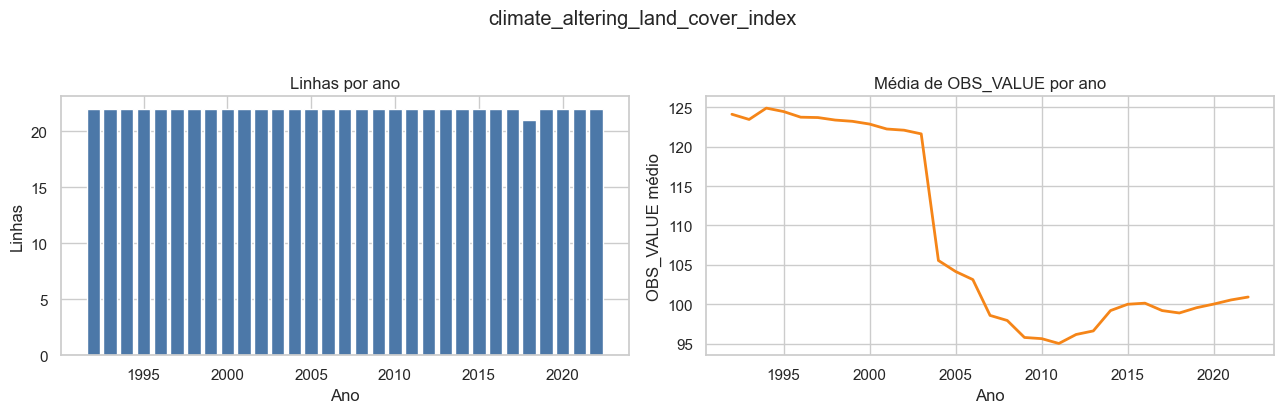

In [5]:
explore_folder('climate_altering_land_cover_index')

## 3.2. `coastline`: Coastline

Tipo informado nos metadados: `stac_geospatial`.

In [6]:
explore_folder('coastline')

Dataset geoespacial: coastline
Metadados


,field,value
0,title,Coastline
1,type,stac_geospatial
2,downloaded_at_utc,2026-06-10T17:17:15+00:00
3,source_url,https://pacificdata.org/data/dataset/landsat-coastlines
4,stac_collection_url,https://stac.prod.digitalearthpacific.io/collections/dep_ls_coastlines


Arquivos da pasta


,file,extension,size_mb,is_file
0,collection.json,.json,0.00,True
1,dep_ls_coastlines_0-7-0-55.gpkg,.gpkg,"1,883.36",True
2,dep_ls_coastlines_0-7-0-55.pmtiles,.pmtiles,371.22,True
3,metadata.json,.json,0.00,True
4,wmts.xml,.xml,0.03,True


Resumo STAC collection.json


,value
id,dep_ls_coastlines
title,Landsat Coastlines
license,CC-BY-4.0
description,Annual coastline data derived from Landsat imagery.
extent,"{'spatial': {'bbox': [[-180, -90, 180, 90]]}, 'temporal': {'interval': [['1980-01-01T00:00:00Z', None]]}}"


... (2 outputs left out)

Camadas GeoPackage

,gpkg_file,size_mb,layer,geometry_type
0,dep_ls_coastlines_0-7-0-55.gpkg,"1,883.36",shorelines_annual,MultiLineString
1,dep_ls_coastlines_0-7-0-55.gpkg,"1,883.36",rates_of_change,Point
2,dep_ls_coastlines_0-7-0-55.gpkg,"1,883.36",hotspots_zoom_1,Point
3,dep_ls_coastlines_0-7-0-55.gpkg,"1,883.36",hotspots_zoom_2,Point
4,dep_ls_coastlines_0-7-0-55.gpkg,"1,883.36",hotspots_zoom_3,Point
5,dep_ls_coastlines_0-7-0-55.gpkg,"1,883.36",layer_styles,Point


Arquivos PMTiles


,file,size_mb
0,dep_ls_coastlines_0-7-0-55.pmtiles,371.22


## 3.3. `crop_yield`: Crop yield

Tipo informado nos metadados: `dotstat_csv`.

Dataset: crop_yield
Metadados


,field,value
0,title,Crop yield
1,type,dotstat_csv
2,dataflow,DF_CLIMATE_CHANGE
3,key,A.CROP_YIELD.
4,downloaded_at_utc,2026-06-10T17:17:15+00:00
5,source_url,"https://stats.pacificdata.org/vis?lc=en&df[ds]=SPC2&df[id]=DF_CLIMATE_CHANGE&df[ag]=SPC&df[vs]=1.0&av=true&dq=A.CROP_YIELD.&pd=,&to[TIME_PERIOD]=false"
6,api_url,"https://stats-nsi-stable.pacificdata.org/rest/data/SPC,DF_CLIMATE_CHANGE,1.0/A.CROP_YIELD.?dimensionAtObservation=AllDimensions&format=csv"


Arquivos da pasta


,file,extension,size_mb,is_file
0,data.csv,.csv,0.06,True
1,metadata.json,.json,0.00,True


Estrutura


,dataset,rows,columns,memory_mb,duplicate_rows,duplicate_rows_pct,empty_columns,columns_list
0,crop_yield,900,12,0.33,0,0.00,"OBS_STATUS, ERROR_TYPE, ERROR_VAL, REPORTING_TYPE, OBS_COMMENT","DATAFLOW, FREQ, CLIMATE_CHANGE_INDICATORS, GEO_PICT, TIME_PERIOD, OBS_VALUE, OBS_STATUS, UNIT_MEASURE, ERROR_TYPE, ERROR_VAL, REPORTING_TYPE, OBS_COMMENT"


... (6 outputs left out)

Resumo de OBS_VALUE


,valid_rows,missing_rows,missing_pct,min,p25,median,mean,p75,max,std,negative_values,zero_values
0,900,0,0.00,510.00,"3,823.52","5,842.25","7,864.02","7,182.15","91,566.00","10,399.60",0,0


Categorias mais frequentes


,column,value,rows,rows_pct
0,GEO_PICT,VU,64,7.11
1,GEO_PICT,TO,64,7.11
2,GEO_PICT,NC,64,7.11
3,GEO_PICT,NU,64,7.11
4,GEO_PICT,KI,64,7.11
5,GEO_PICT,PG,64,7.11
6,GEO_PICT,WS,64,7.11
7,GEO_PICT,TV,64,7.11
8,GEO_PICT,FJ,64,7.11
9,GEO_PICT,CK,64,7.11


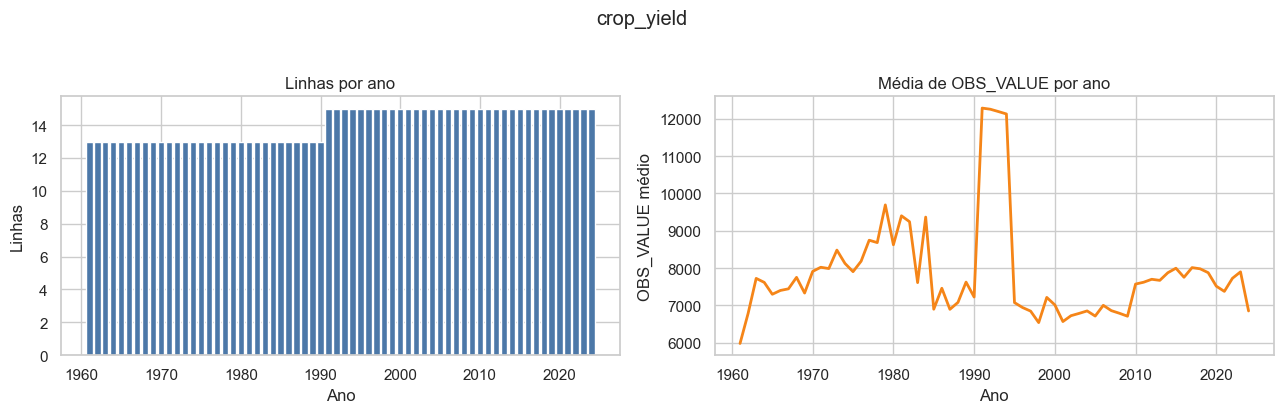

In [7]:
explore_folder('crop_yield')

## 3.4. `crop_yield_disaggregated`: Crop yield - disaggregated

Tipo informado nos metadados: `dotstat_csv`.

Dataset: crop_yield_disaggregated
Metadados


,field,value
0,title,Crop yield - disaggregated
1,type,dotstat_csv
2,dataflow,DF_AGRICULTURAL_PRODUCTION
3,key,A...
4,downloaded_at_utc,2026-06-10T17:17:15+00:00
5,source_url,"https://stats.pacificdata.org/vis?lc=en&df[ds]=SPC2&df[id]=DF_AGRICULTURAL_PRODUCTION&df[ag]=SPC&df[vs]=1.0&av=true&dq=A...&pd=,&to[TIME_PERIOD]=false"
6,api_url,"https://stats-nsi-stable.pacificdata.org/rest/data/SPC,DF_AGRICULTURAL_PRODUCTION,1.0/A...?dimensionAtObservation=AllDimensions&format=csv"


Arquivos da pasta


,file,extension,size_mb,is_file
0,data.csv,.csv,1.57,True
1,metadata.json,.json,0.00,True


Estrutura


,dataset,rows,columns,memory_mb,duplicate_rows,duplicate_rows_pct,empty_columns,columns_list
0,crop_yield_disaggregated,20725,13,8.99,0,0.00,"OBS_STATUS, ERROR_TYPE, ERROR_VAL, REPORTING_TYPE, OBS_COMMENT","DATAFLOW, FREQ, GEO_PICT, AGRICULTURE_PRODUCTION_ITEM, AGRICULTURE_PRODUCTION_TYPE, TIME_PERIOD, OBS_VALUE, OBS_STATUS, UNIT_MEASURE, ERROR_TYPE, ERROR_VAL,..."


... (6 outputs left out)

Resumo de OBS_VALUE


,valid_rows,missing_rows,missing_pct,min,p25,median,mean,p75,max,std,negative_values,zero_values
0,20725,0,0.00,1.00,191.00,"2,312.50","6,024.11","9,090.90","99,000.00","8,837.62",0,0


Categorias mais frequentes


,column,value,rows,rows_pct
0,GEO_PICT,PG,2918,14.08
1,GEO_PICT,FJ,2640,12.74
2,GEO_PICT,PF,2619,12.64
3,GEO_PICT,NC,1816,8.76
4,GEO_PICT,TO,1796,8.67
5,GEO_PICT,WS,1762,8.50
6,GEO_PICT,CK,1639,7.91
7,GEO_PICT,SB,1445,6.97
8,GEO_PICT,VU,1389,6.70
9,GEO_PICT,NU,997,4.81


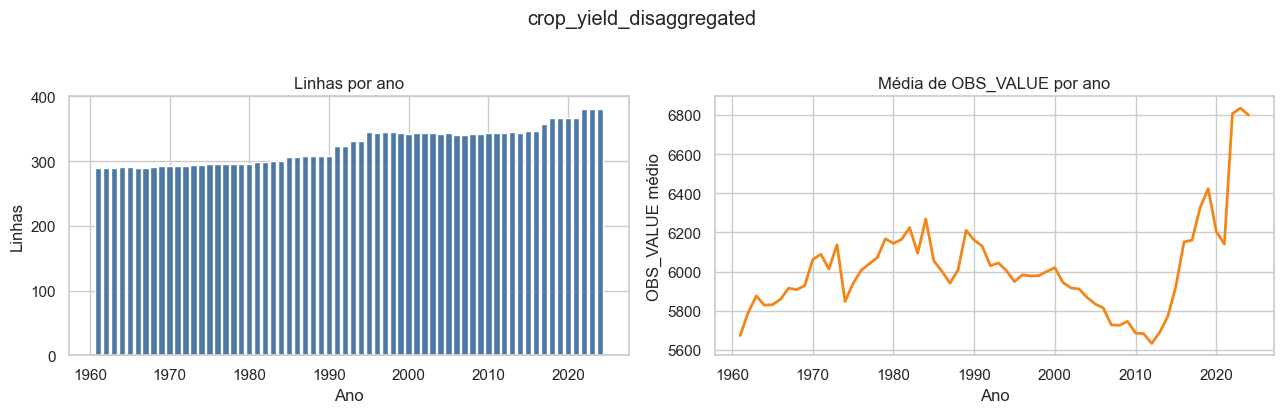

In [8]:
explore_folder('crop_yield_disaggregated')

## 3.5. `direct_disaster_economic_loss`: Direct disaster economic loss

Tipo informado nos metadados: `dotstat_csv`.

Dataset: direct_disaster_economic_loss
Metadados


,field,value
0,title,Direct disaster economic loss
1,type,dotstat_csv
2,dataflow,DF_SDG_11
3,key,A.VC_DSR_AALT...._T.....
4,downloaded_at_utc,2026-06-10T17:17:15+00:00
5,source_url,"https://stats.pacificdata.org/vis?lc=en&df[ds]=ds%3ASPC2&df[id]=DF_SDG_11&df[ag]=SPC&df[vs]=3.0&dq=A.VC_DSR_AALT...._T.....&pd=,&to[TIME_PERIOD]=false"
6,api_url,"https://stats-nsi-stable.pacificdata.org/rest/data/SPC,DF_SDG_11,3.0/A.VC_DSR_AALT...._T.....?dimensionAtObservation=AllDimensions&format=csv"


Arquivos da pasta


,file,extension,size_mb,is_file
0,data.csv,.csv,0.01,True
1,metadata.json,.json,0.00,True


Estrutura


,dataset,rows,columns,memory_mb,duplicate_rows,duplicate_rows_pct,empty_columns,columns_list
0,direct_disaster_economic_loss,39,20,0.05,0,0.00,OBS_STATUS,"DATAFLOW, FREQ, INDICATOR, GEO_PICT, SEX, AGE, URBANIZATION, INCOME, EDUCATION, OCCUPATION, COMPOSITE_BREAKDOWN, DISABILITY, TIME_PERIOD, OBS_VALUE (+6)"


... (6 outputs left out)

Resumo de OBS_VALUE


,valid_rows,missing_rows,missing_pct,min,p25,median,mean,p75,max,std,negative_values,zero_values
0,39,0,0.00,4.90,"367,852.50","1,781,682.00","21,964,934.90","19,435,031.50","374,109,863.00","63,248,998.06",0,0


Categorias mais frequentes


,column,value,rows,rows_pct
0,GEO_PICT,FJ,7,17.95
1,GEO_PICT,VU,6,15.38
2,GEO_PICT,TO,5,12.82
3,GEO_PICT,PG,4,10.26
4,GEO_PICT,SB,4,10.26
5,GEO_PICT,FM,3,7.69
6,GEO_PICT,MH,3,7.69
7,GEO_PICT,KI,2,5.13
8,GEO_PICT,PW,2,5.13
9,GEO_PICT,WS,1,2.56


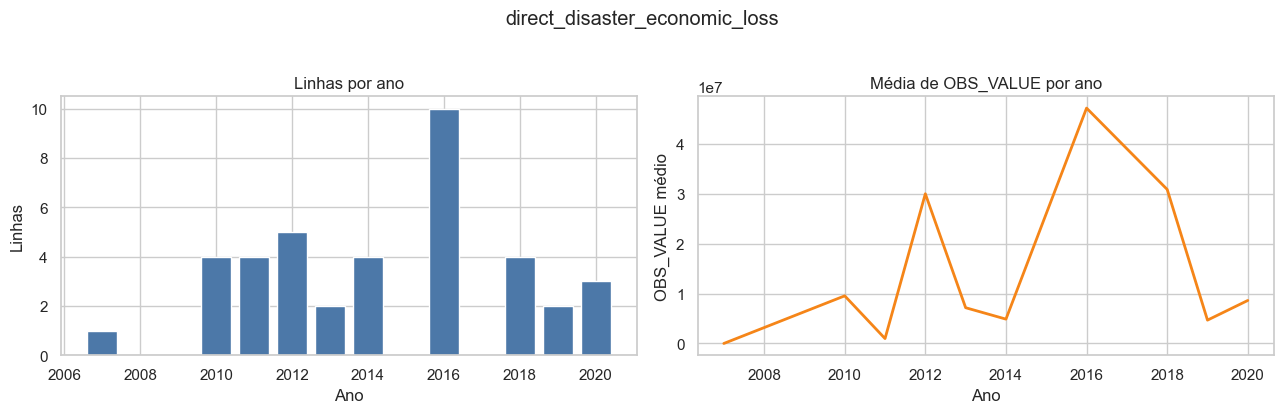

In [9]:
explore_folder('direct_disaster_economic_loss')

## 3.6. `disaster_directly_affected_persons`: Number of directly affected persons attributed to disasters

Tipo informado nos metadados: `dotstat_csv`.

Dataset: disaster_directly_affected_persons
Metadados


,field,value
0,title,Number of directly affected persons attributed to disasters
1,type,dotstat_csv
2,dataflow,DF_SDG_11
3,key,A.VC_DSR_AFFCT.........
4,downloaded_at_utc,2026-06-10T17:17:15+00:00
5,source_url,"https://stats.pacificdata.org/vis?lc=en&df[ds]=ds%3ASPC2&df[id]=DF_SDG_11&df[ag]=SPC&df[vs]=3.0&dq=A.VC_DSR_AFFCT.........&pd=,&to[TIME_PERIOD]=false&lb=bt"
6,api_url,"https://stats-nsi-stable.pacificdata.org/rest/data/SPC,DF_SDG_11,3.0/A.VC_DSR_AFFCT.........?dimensionAtObservation=AllDimensions&format=csv"


Arquivos da pasta


,file,extension,size_mb,is_file
0,data.csv,.csv,0.07,True
1,metadata.json,.json,0.00,True


Estrutura


,dataset,rows,columns,memory_mb,duplicate_rows,duplicate_rows_pct,empty_columns,columns_list
0,disaster_directly_affected_persons,174,20,0.23,0,0.00,OBS_STATUS,"DATAFLOW, FREQ, INDICATOR, GEO_PICT, SEX, AGE, URBANIZATION, INCOME, EDUCATION, OCCUPATION, COMPOSITE_BREAKDOWN, DISABILITY, TIME_PERIOD, OBS_VALUE (+6)"


... (6 outputs left out)

Resumo de OBS_VALUE


,valid_rows,missing_rows,missing_pct,min,p25,median,mean,p75,max,std,negative_values,zero_values
0,174,0,0.00,0,0.00,15.00,"14,874.84","2,033.50",633584,"59,839.05",0,75


Categorias mais frequentes


,column,value,rows,rows_pct
0,GEO_PICT,FJ,18,10.34
1,GEO_PICT,SB,17,9.77
2,GEO_PICT,VU,16,9.20
3,GEO_PICT,TO,16,9.20
4,GEO_PICT,WS,15,8.62
5,GEO_PICT,MH,13,7.47
6,GEO_PICT,PG,13,7.47
7,GEO_PICT,FM,11,6.32
8,GEO_PICT,TV,9,5.17
9,GEO_PICT,KI,8,4.60


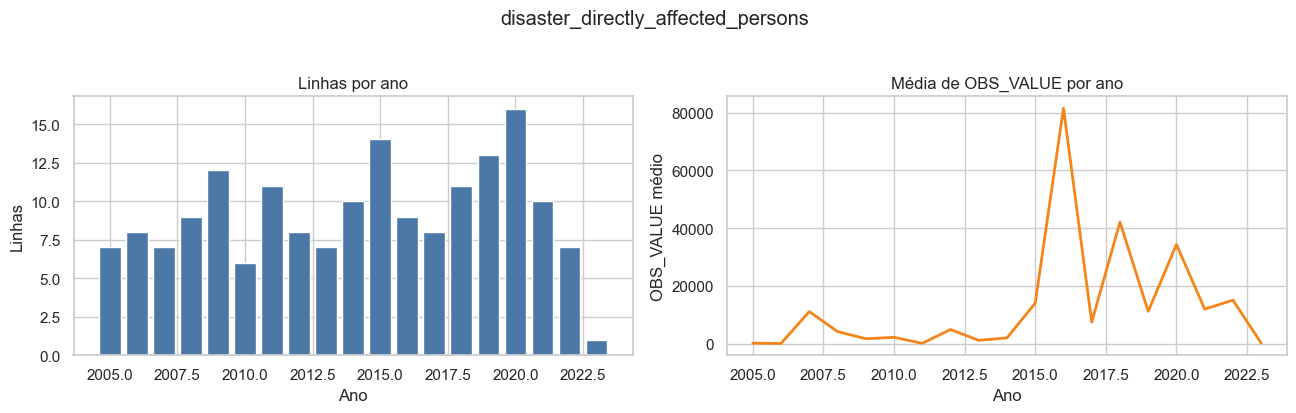

In [10]:
explore_folder('disaster_directly_affected_persons')

## 3.7. `environmental_taxes`: Environmental taxes

Tipo informado nos metadados: `dotstat_csv`.

Dataset: environmental_taxes
Metadados


,field,value
0,title,Environmental taxes
1,type,dotstat_csv
2,dataflow,DF_CLIMATE_CHANGE
3,key,A.ENV_TAXES.
4,downloaded_at_utc,2026-06-10T17:17:15+00:00
5,source_url,"https://stats.pacificdata.org/vis?lc=en&df[ds]=SPC2&df[id]=DF_CLIMATE_CHANGE&df[ag]=SPC&df[vs]=1.0&av=true&dq=A.ENV_TAXES.&pd=,&to[TIME_PERIOD]=false"
6,api_url,"https://stats-nsi-stable.pacificdata.org/rest/data/SPC,DF_CLIMATE_CHANGE,1.0/A.ENV_TAXES.?dimensionAtObservation=AllDimensions&format=csv"


Arquivos da pasta


,file,extension,size_mb,is_file
0,data.csv,.csv,0.00,True
1,metadata.json,.json,0.00,True


Estrutura


,dataset,rows,columns,memory_mb,duplicate_rows,duplicate_rows_pct,empty_columns,columns_list
0,environmental_taxes,59,12,0.02,0,0.00,"OBS_STATUS, ERROR_TYPE, ERROR_VAL, OBS_COMMENT","DATAFLOW, FREQ, CLIMATE_CHANGE_INDICATORS, GEO_PICT, TIME_PERIOD, OBS_VALUE, OBS_STATUS, UNIT_MEASURE, ERROR_TYPE, ERROR_VAL, REPORTING_TYPE, OBS_COMMENT"


... (6 outputs left out)

Resumo de OBS_VALUE


,valid_rows,missing_rows,missing_pct,min,p25,median,mean,p75,max,std,negative_values,zero_values
0,59,0,0.00,0.00,0.02,0.38,1.38,1.95,6.20,1.84,0,1


Categorias mais frequentes


,column,value,rows,rows_pct
0,GEO_PICT,PG,21,35.59
1,GEO_PICT,SB,14,23.73
2,GEO_PICT,FJ,11,18.64
3,GEO_PICT,NR,9,15.25
4,GEO_PICT,WS,4,6.78
5,UNIT_MEASURE,PERCENT,59,100.00
6,OBS_STATUS,[missing],59,100.00
7,CLIMATE_CHANGE_INDICATORS,ENV_TAXES,59,100.00


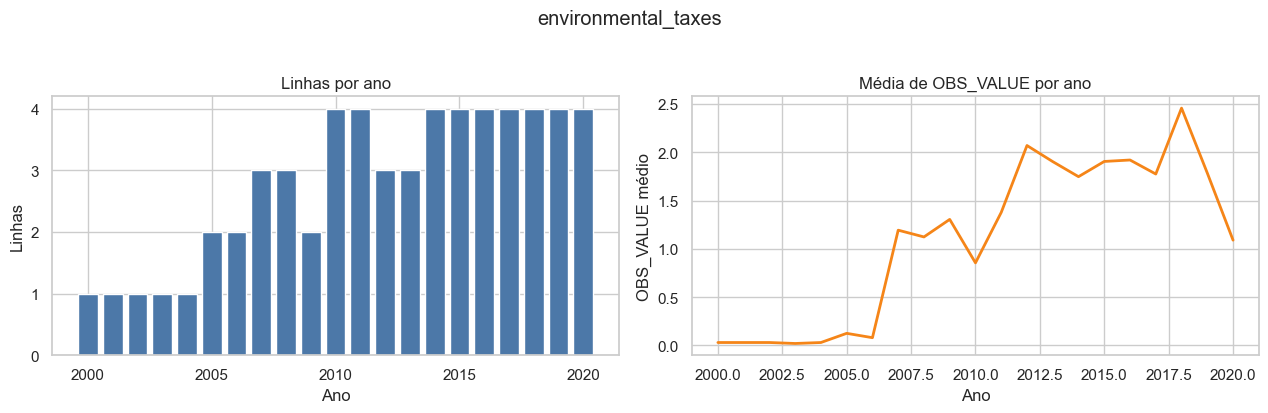

In [11]:
explore_folder('environmental_taxes')

## 3.8. `environmental_taxes_disaggregated`: Environmental taxes - disaggregated

Tipo informado nos metadados: `dotstat_csv`.

Dataset: environmental_taxes_disaggregated
Metadados


,field,value
0,title,Environmental taxes - disaggregated
1,type,dotstat_csv
2,dataflow,DF_ENV_TAXES
3,key,A..
4,downloaded_at_utc,2026-06-10T17:17:15+00:00
5,source_url,"https://stats.pacificdata.org/vis?lc=en&df[ds]=SPC2&df[id]=DF_ENV_TAXES&df[ag]=SPC&df[vs]=1.0&av=true&dq=A..&pd=,&to[TIME_PERIOD]=false"
6,api_url,"https://stats-nsi-stable.pacificdata.org/rest/data/SPC,DF_ENV_TAXES,1.0/A..?dimensionAtObservation=AllDimensions&format=csv"


Arquivos da pasta


,file,extension,size_mb,is_file
0,data.csv,.csv,0.03,True
1,metadata.json,.json,0.00,True


Estrutura


,dataset,rows,columns,memory_mb,duplicate_rows,duplicate_rows_pct,empty_columns,columns_list
0,environmental_taxes_disaggregated,519,12,0.21,0,0.00,"OBS_STATUS, ERROR_TYPE, ERROR_VAL, OBS_COMMENT","DATAFLOW, FREQ, GEO_PICT, ENV_TAXES, TIME_PERIOD, OBS_VALUE, OBS_STATUS, UNIT_MEASURE, ERROR_TYPE, ERROR_VAL, REPORTING_TYPE, OBS_COMMENT"


... (6 outputs left out)

Resumo de OBS_VALUE


,valid_rows,missing_rows,missing_pct,min,p25,median,mean,p75,max,std,negative_values,zero_values
0,519,0,0.00,0.00,0.00,0.00,0.16,0.00,6.20,0.76,0,457


Categorias mais frequentes


,column,value,rows,rows_pct
0,GEO_PICT,PG,102,19.65
1,GEO_PICT,SB,95,18.30
2,GEO_PICT,NR,90,17.34
3,GEO_PICT,CK,81,15.61
4,GEO_PICT,WS,79,15.22
5,GEO_PICT,FJ,72,13.87
6,UNIT_MEASURE,PERCENT,519,100.00
7,OBS_STATUS,[missing],519,100.00
8,ENV_TAXES,POLLN,156,30.06
9,ENV_TAXES,ENRG,139,26.78


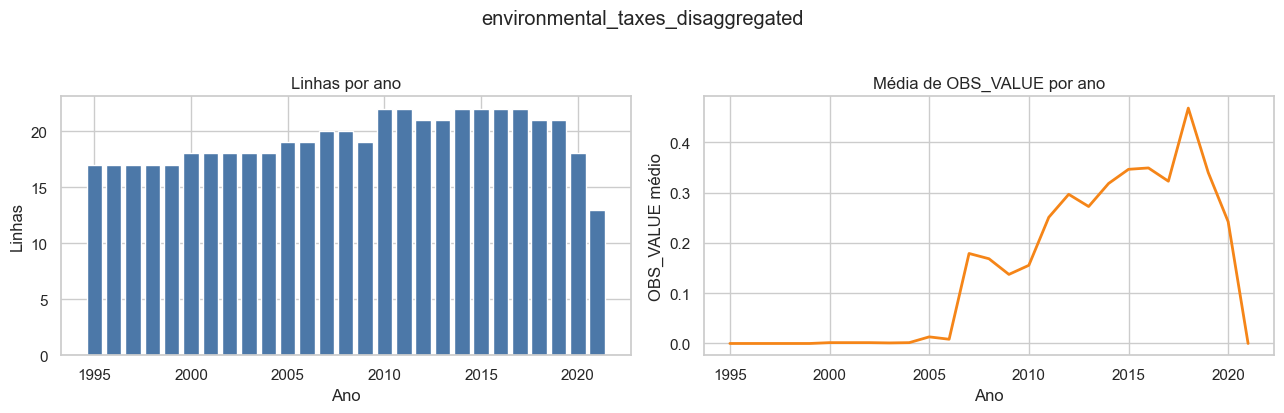

In [12]:
explore_folder('environmental_taxes_disaggregated')

## 3.9. `fisheries_management_measures_and_arrangements`: Fisheries management measures in place and multilateral and bilateral fisheries management arrangements

Tipo informado nos metadados: `dotstat_csv`.

Dataset: fisheries_management_measures_and_arrangements
Metadados


,field,value
0,title,Fisheries management measures in place and multilateral and bilateral fisheries management arrangements
1,type,dotstat_csv
2,dataflow,DF_CLIMATE_CHANGE
3,key,A.FISH_MNGT_MULT_BILAT_ARGMT.
4,downloaded_at_utc,2026-06-10T17:17:15+00:00
5,source_url,"https://stats.pacificdata.org/vis?lc=en&df[ds]=SPC2&df[id]=DF_CLIMATE_CHANGE&df[ag]=SPC&df[vs]=1.0&av=true&dq=A.FISH_MNGT_MULT_BILAT_ARGMT.&pd=,&to[TIME_PER..."
6,api_url,"https://stats-nsi-stable.pacificdata.org/rest/data/SPC,DF_CLIMATE_CHANGE,1.0/A.FISH_MNGT_MULT_BILAT_ARGMT.?dimensionAtObservation=AllDimensions&format=csv"


Arquivos da pasta


,file,extension,size_mb,is_file
0,data.csv,.csv,0.11,True
1,metadata.json,.json,0.00,True


Estrutura


,dataset,rows,columns,memory_mb,duplicate_rows,duplicate_rows_pct,empty_columns,columns_list
0,fisheries_management_measures_and_arrangements,1563,12,0.67,0,0.00,"OBS_STATUS, ERROR_TYPE, ERROR_VAL, OBS_COMMENT","DATAFLOW, FREQ, CLIMATE_CHANGE_INDICATORS, GEO_PICT, TIME_PERIOD, OBS_VALUE, OBS_STATUS, UNIT_MEASURE, ERROR_TYPE, ERROR_VAL, REPORTING_TYPE, OBS_COMMENT"


... (6 outputs left out)

Resumo de OBS_VALUE


,valid_rows,missing_rows,missing_pct,min,p25,median,mean,p75,max,std,negative_values,zero_values
0,1563,0,0.00,1,3.00,8.00,18.08,28.00,93,20.41,0,0


Categorias mais frequentes


,column,value,rows,rows_pct
0,GEO_PICT,TO,124,7.93
1,GEO_PICT,VU,110,7.04
2,GEO_PICT,TV,108,6.91
3,GEO_PICT,NR,91,5.82
4,GEO_PICT,FJ,85,5.44
5,GEO_PICT,SB,75,4.80
6,GEO_PICT,PG,75,4.80
7,GEO_PICT,NC,72,4.61
8,GEO_PICT,WS,72,4.61
9,GEO_PICT,AS,72,4.61


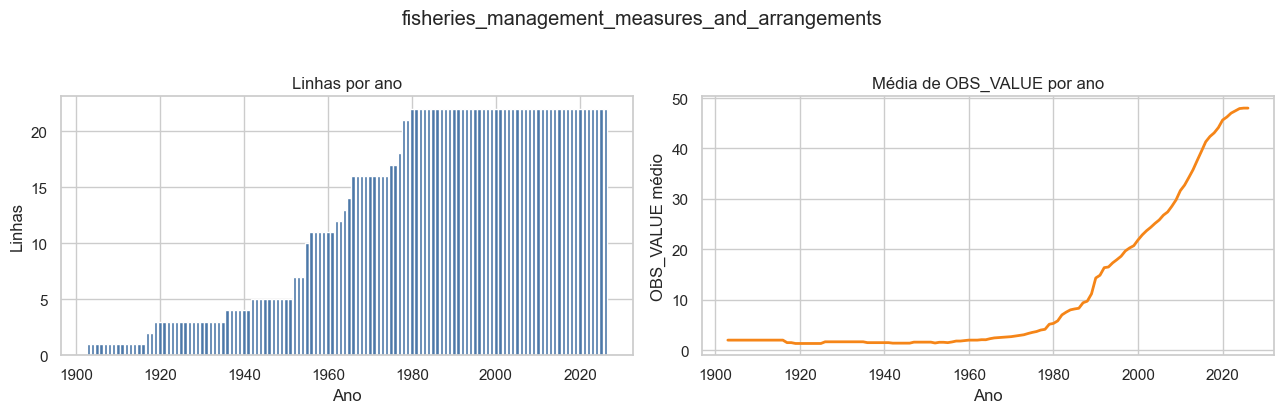

In [13]:
explore_folder('fisheries_management_measures_and_arrangements')

## 3.10. `greenhouse_gas_emissions_per_capita`: Greenhouse gas emissions per capita

Tipo informado nos metadados: `dotstat_csv`.

Dataset: greenhouse_gas_emissions_per_capita
Metadados


,field,value
0,title,Greenhouse gas emissions per capita
1,type,dotstat_csv
2,dataflow,DF_CLIMATE_CHANGE
3,key,A.GHG_EMI_CAPITA.
4,downloaded_at_utc,2026-06-10T17:17:15+00:00
5,source_url,"https://stats.pacificdata.org/vis?lc=en&df[ds]=SPC2&df[id]=DF_CLIMATE_CHANGE&df[ag]=SPC&df[vs]=1.0&av=true&dq=A.GHG_EMI_CAPITA.&pd=,&to[TIME_PERIOD]=false"
6,api_url,"https://stats-nsi-stable.pacificdata.org/rest/data/SPC,DF_CLIMATE_CHANGE,1.0/A.GHG_EMI_CAPITA.?dimensionAtObservation=AllDimensions&format=csv"


Arquivos da pasta


,file,extension,size_mb,is_file
0,data.csv,.csv,0.06,True
1,metadata.json,.json,0.00,True


Estrutura


,dataset,rows,columns,memory_mb,duplicate_rows,duplicate_rows_pct,empty_columns,columns_list
0,greenhouse_gas_emissions_per_capita,935,12,0.39,0,0.00,"OBS_STATUS, ERROR_TYPE, ERROR_VAL, OBS_COMMENT","DATAFLOW, FREQ, CLIMATE_CHANGE_INDICATORS, GEO_PICT, TIME_PERIOD, OBS_VALUE, OBS_STATUS, UNIT_MEASURE, ERROR_TYPE, ERROR_VAL, REPORTING_TYPE, OBS_COMMENT"


... (6 outputs left out)

Resumo de OBS_VALUE


,valid_rows,missing_rows,missing_pct,min,p25,median,mean,p75,max,std,negative_values,zero_values
0,935,0,0.00,0.00,0.20,0.90,9.54,2.70,209.50,32.41,0,2


Categorias mais frequentes


,column,value,rows,rows_pct
0,GEO_PICT,NR,55,5.88
1,GEO_PICT,TO,55,5.88
2,GEO_PICT,TV,55,5.88
3,GEO_PICT,AS,55,5.88
4,GEO_PICT,WS,55,5.88
5,GEO_PICT,PW,55,5.88
6,GEO_PICT,VU,55,5.88
7,GEO_PICT,FM,55,5.88
8,GEO_PICT,PF,55,5.88
9,GEO_PICT,KI,55,5.88


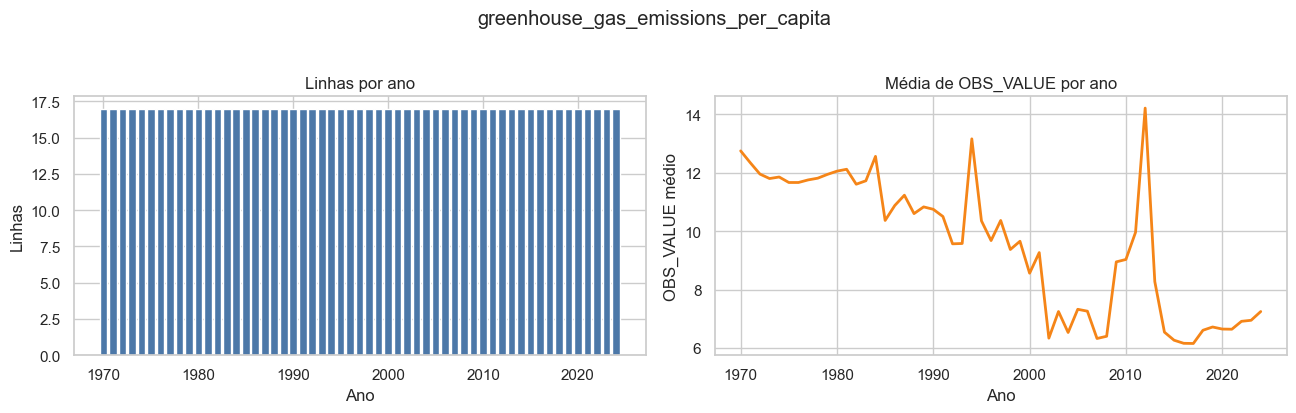

In [14]:
explore_folder('greenhouse_gas_emissions_per_capita')

## 3.11. `livestock_yield`: Livestock yield

Tipo informado nos metadados: `dotstat_csv`.

Dataset: livestock_yield
Metadados


,field,value
0,title,Livestock yield
1,type,dotstat_csv
2,dataflow,DF_CLIMATE_CHANGE
3,key,A.LVST_YIELD.
4,downloaded_at_utc,2026-06-10T17:17:15+00:00
5,source_url,"https://stats.pacificdata.org/vis?lc=en&df[ds]=SPC2&df[id]=DF_CLIMATE_CHANGE&df[ag]=SPC&df[vs]=1.0&av=true&dq=A.LVST_YIELD.&pd=,&to[TIME_PERIOD]=false"
6,api_url,"https://stats-nsi-stable.pacificdata.org/rest/data/SPC,DF_CLIMATE_CHANGE,1.0/A.LVST_YIELD.?dimensionAtObservation=AllDimensions&format=csv"


Arquivos da pasta


,file,extension,size_mb,is_file
0,data.csv,.csv,0.06,True
1,metadata.json,.json,0.00,True


Estrutura


,dataset,rows,columns,memory_mb,duplicate_rows,duplicate_rows_pct,empty_columns,columns_list
0,livestock_yield,866,12,0.32,0,0.00,"OBS_STATUS, ERROR_TYPE, ERROR_VAL, REPORTING_TYPE, OBS_COMMENT","DATAFLOW, FREQ, CLIMATE_CHANGE_INDICATORS, GEO_PICT, TIME_PERIOD, OBS_VALUE, OBS_STATUS, UNIT_MEASURE, ERROR_TYPE, ERROR_VAL, REPORTING_TYPE, OBS_COMMENT"


... (6 outputs left out)

Resumo de OBS_VALUE


,valid_rows,missing_rows,missing_pct,min,p25,median,mean,p75,max,std,negative_values,zero_values
0,866,0,0.00,31.80,655.07,"1,607.85","1,939.93","2,546.75","10,876.70","1,723.29",0,0


Categorias mais frequentes


,column,value,rows,rows_pct
0,GEO_PICT,TV,64,7.39
1,GEO_PICT,KI,64,7.39
2,GEO_PICT,NR,64,7.39
3,GEO_PICT,CK,64,7.39
4,GEO_PICT,FJ,64,7.39
5,GEO_PICT,SB,64,7.39
6,GEO_PICT,PF,64,7.39
7,GEO_PICT,TO,64,7.39
8,GEO_PICT,VU,64,7.39
9,GEO_PICT,NC,64,7.39


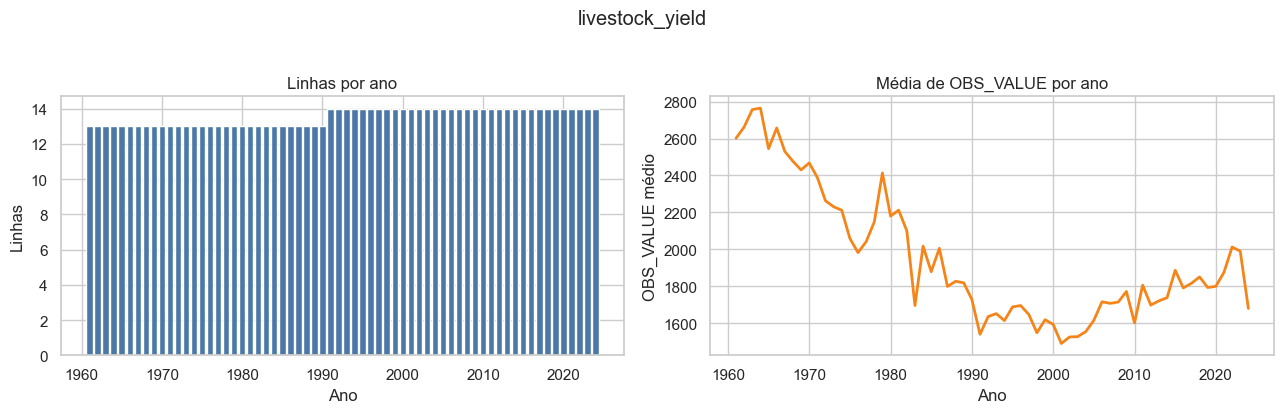

In [15]:
explore_folder('livestock_yield')

## 3.12. `livestock_yield_disaggregated`: Livestock yield - disaggregated

Tipo informado nos metadados: `dotstat_csv`.

Dataset: livestock_yield_disaggregated
Metadados


,field,value
0,title,Livestock yield - disaggregated
1,type,dotstat_csv
2,dataflow,DF_AGRICULTURAL_PRODUCTION
3,key,A...
4,downloaded_at_utc,2026-06-10T17:17:15+00:00
5,source_url,"https://stats.pacificdata.org/vis?lc=en&df[ds]=SPC2&df[id]=DF_AGRICULTURAL_PRODUCTION&df[ag]=SPC&df[vs]=1.0&av=true&dq=A...&pd=,&to[TIME_PERIOD]=false"
6,api_url,"https://stats-nsi-stable.pacificdata.org/rest/data/SPC,DF_AGRICULTURAL_PRODUCTION,1.0/A...?dimensionAtObservation=AllDimensions&format=csv"


Arquivos da pasta


,file,extension,size_mb,is_file
0,data.csv,.csv,1.57,True
1,metadata.json,.json,0.00,True


Estrutura

,dataset,rows,columns,memory_mb,duplicate_rows,duplicate_rows_pct,empty_columns,columns_list
0,livestock_yield_disaggregated,20725,13,8.99,0,0.00,"OBS_STATUS, ERROR_TYPE, ERROR_VAL, REPORTING_TYPE, OBS_COMMENT","DATAFLOW, FREQ, GEO_PICT, AGRICULTURE_PRODUCTION_ITEM, AGRICULTURE_PRODUCTION_TYPE, TIME_PERIOD, OBS_VALUE, OBS_STATUS, UNIT_MEASURE, ERROR_TYPE, ERROR_VAL,..."


... (6 outputs left out)

Resumo de OBS_VALUE


,valid_rows,missing_rows,missing_pct,min,p25,median,mean,p75,max,std,negative_values,zero_values
0,20725,0,0.00,1.00,191.00,"2,312.50","6,024.11","9,090.90","99,000.00","8,837.62",0,0


Categorias mais frequentes


,column,value,rows,rows_pct
0,GEO_PICT,PG,2918,14.08
1,GEO_PICT,FJ,2640,12.74
2,GEO_PICT,PF,2619,12.64
3,GEO_PICT,NC,1816,8.76
4,GEO_PICT,TO,1796,8.67
5,GEO_PICT,WS,1762,8.50
6,GEO_PICT,CK,1639,7.91
7,GEO_PICT,SB,1445,6.97
8,GEO_PICT,VU,1389,6.70
9,GEO_PICT,NU,997,4.81


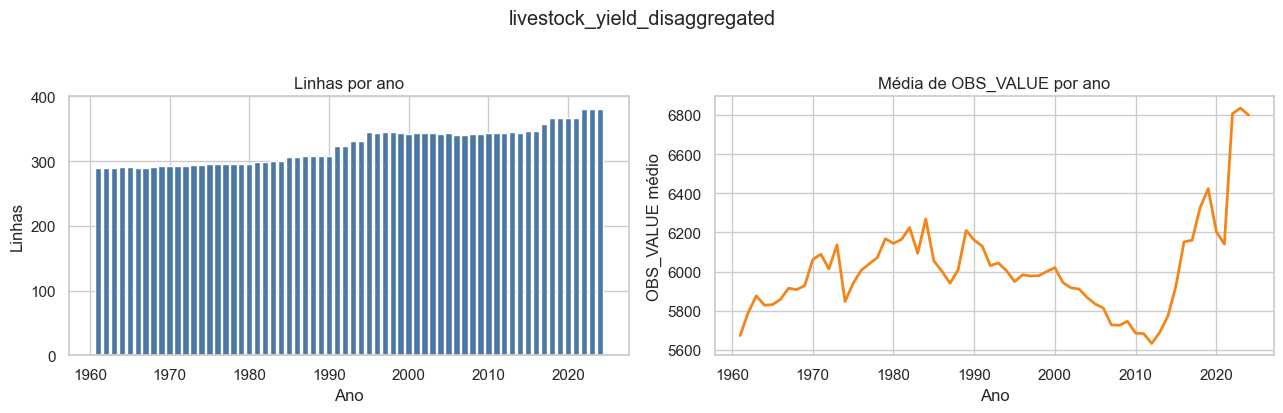

In [16]:
explore_folder('livestock_yield_disaggregated')

## 3.13. `mean_sea_surface_temperature_anomalies`: Mean sea surface temperature anomalies

Tipo informado nos metadados: `dotstat_csv`.

Dataset: mean_sea_surface_temperature_anomalies
Metadados


,field,value
0,title,Mean sea surface temperature anomalies
1,type,dotstat_csv
2,dataflow,DF_CLIMATE_CHANGE
3,key,A.SST_ANOM.
4,downloaded_at_utc,2026-06-10T17:17:15+00:00
5,source_url,"https://stats.pacificdata.org/vis?lc=en&df[ds]=SPC2&df[id]=DF_CLIMATE_CHANGE&df[ag]=SPC&df[vs]=1.0&av=true&dq=A.SST_ANOM.&pd=,&to[TIME_PERIOD]=false"
6,api_url,"https://stats-nsi-stable.pacificdata.org/rest/data/SPC,DF_CLIMATE_CHANGE,1.0/A.SST_ANOM.?dimensionAtObservation=AllDimensions&format=csv"


Arquivos da pasta


,file,extension,size_mb,is_file
0,data.csv,.csv,0.25,True
1,metadata.json,.json,0.00,True


Estrutura


,dataset,rows,columns,memory_mb,duplicate_rows,duplicate_rows_pct,empty_columns,columns_list
0,mean_sea_surface_temperature_anomalies,3696,12,1.71,0,0.00,"OBS_STATUS, OBS_COMMENT","DATAFLOW, FREQ, CLIMATE_CHANGE_INDICATORS, GEO_PICT, TIME_PERIOD, OBS_VALUE, OBS_STATUS, UNIT_MEASURE, ERROR_TYPE, ERROR_VAL, REPORTING_TYPE, OBS_COMMENT"


... (6 outputs left out)

Resumo de OBS_VALUE


,valid_rows,missing_rows,missing_pct,min,p25,median,mean,p75,max,std,negative_values,zero_values
0,3696,0,0.00,-2.00,-0.40,-0.20,-0.14,0.10,1.10,0.38,2295,350


Categorias mais frequentes


,column,value,rows,rows_pct
0,GEO_PICT,AS,176,4.76
1,GEO_PICT,FJ,176,4.76
2,GEO_PICT,NC,176,4.76
3,GEO_PICT,VU,176,4.76
4,GEO_PICT,TO,176,4.76
5,GEO_PICT,PF,176,4.76
6,GEO_PICT,SB,176,4.76
7,GEO_PICT,TK,176,4.76
8,GEO_PICT,WF,176,4.76
9,GEO_PICT,MH,176,4.76


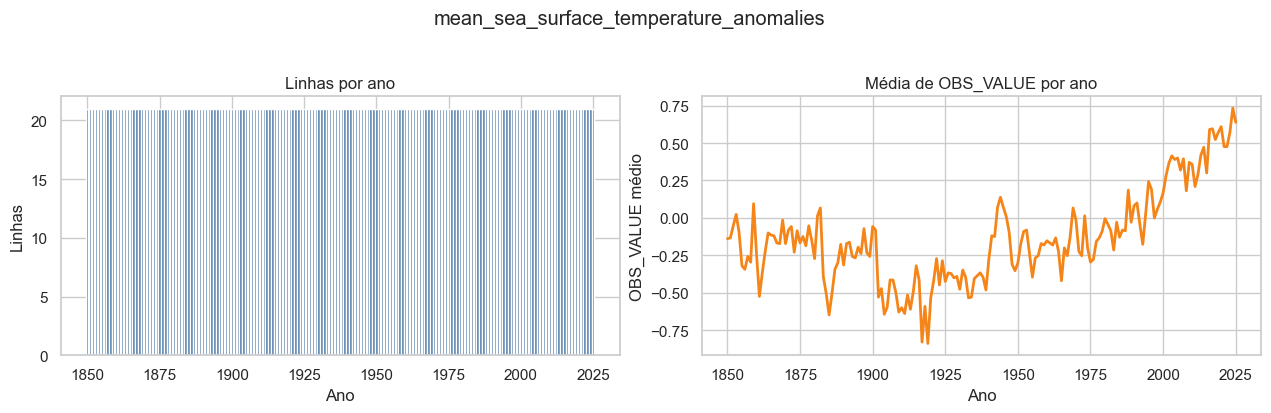

In [17]:
explore_folder('mean_sea_surface_temperature_anomalies')

## 3.14. `mean_surface_temperature_anomalies`: Mean surface temperature anomalies

Tipo informado nos metadados: `dotstat_csv`.

Dataset: mean_surface_temperature_anomalies
Metadados


,field,value
0,title,Mean surface temperature anomalies
1,type,dotstat_csv
2,dataflow,DF_CLIMATE_CHANGE
3,key,A.ST_ANOM.
4,downloaded_at_utc,2026-06-10T17:17:15+00:00
5,source_url,"https://stats.pacificdata.org/vis?lc=en&df[ds]=SPC2&df[id]=DF_CLIMATE_CHANGE&df[ag]=SPC&df[vs]=1.0&av=true&dq=A.ST_ANOM.&pd=,&to[TIME_PERIOD]=false"
6,api_url,"https://stats-nsi-stable.pacificdata.org/rest/data/SPC,DF_CLIMATE_CHANGE,1.0/A.ST_ANOM.?dimensionAtObservation=AllDimensions&format=csv"


Arquivos da pasta


,file,extension,size_mb,is_file
0,data.csv,.csv,0.25,True
1,metadata.json,.json,0.00,True


Estrutura

,dataset,rows,columns,memory_mb,duplicate_rows,duplicate_rows_pct,empty_columns,columns_list
0,mean_surface_temperature_anomalies,3872,12,1.79,0,0.00,"OBS_STATUS, OBS_COMMENT","DATAFLOW, FREQ, CLIMATE_CHANGE_INDICATORS, GEO_PICT, TIME_PERIOD, OBS_VALUE, OBS_STATUS, UNIT_MEASURE, ERROR_TYPE, ERROR_VAL, REPORTING_TYPE, OBS_COMMENT"


... (6 outputs left out)

Resumo de OBS_VALUE


,valid_rows,missing_rows,missing_pct,min,p25,median,mean,p75,max,std,negative_values,zero_values
0,3872,0,0.00,-2.30,-0.40,-0.20,-0.14,0.10,1.20,0.39,2429,363


Categorias mais frequentes


,column,value,rows,rows_pct
0,GEO_PICT,WF,176,4.55
1,GEO_PICT,SB,176,4.55
2,GEO_PICT,PG,176,4.55
3,GEO_PICT,TV,176,4.55
4,GEO_PICT,KI,176,4.55
5,GEO_PICT,NR,176,4.55
6,GEO_PICT,NU,176,4.55
7,GEO_PICT,AS,176,4.55
8,GEO_PICT,FM,176,4.55
9,GEO_PICT,TO,176,4.55


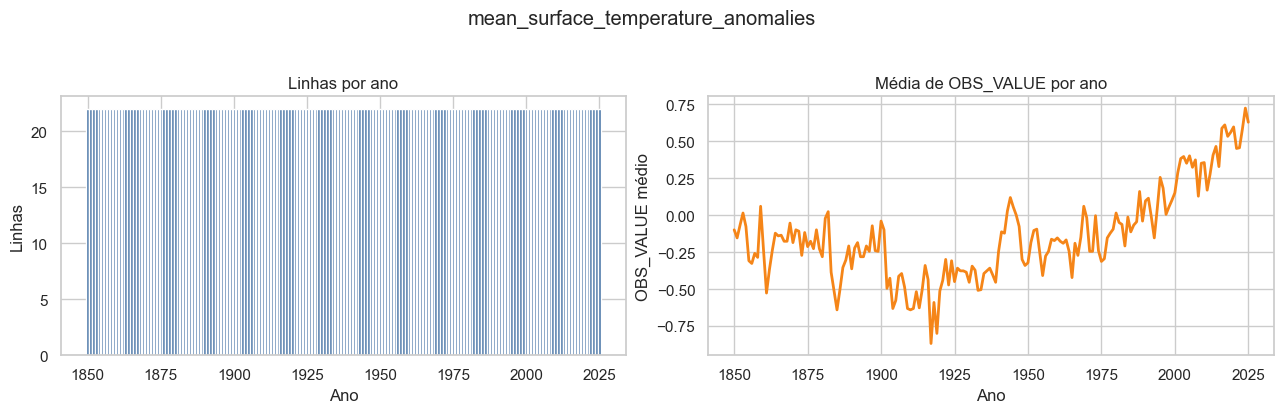

In [18]:
explore_folder('mean_surface_temperature_anomalies')

## 3.15. `meteorological_monitoring_network`: Meteorological monitoring network

Tipo informado nos metadados: `dotstat_csv`.

Dataset: meteorological_monitoring_network
Metadados


,field,value
0,title,Meteorological monitoring network
1,type,dotstat_csv
2,dataflow,DF_CLIMATE_CHANGE
3,key,A.METEO_MONITOR_NET.
4,downloaded_at_utc,2026-06-10T17:17:15+00:00
5,source_url,"https://stats.pacificdata.org/vis?lc=en&df[ds]=SPC2&df[id]=DF_CLIMATE_CHANGE&df[ag]=SPC&df[vs]=1.0&av=true&dq=A.METEO_MONITOR_NET.&pd=,&to[TIME_PERIOD]=false"
6,api_url,"https://stats-nsi-stable.pacificdata.org/rest/data/SPC,DF_CLIMATE_CHANGE,1.0/A.METEO_MONITOR_NET.?dimensionAtObservation=AllDimensions&format=csv"


Arquivos da pasta


,file,extension,size_mb,is_file
0,data.csv,.csv,0.10,True
1,metadata.json,.json,0.00,True


Estrutura


,dataset,rows,columns,memory_mb,duplicate_rows,duplicate_rows_pct,empty_columns,columns_list
0,meteorological_monitoring_network,1650,12,0.69,0,0.00,"OBS_STATUS, ERROR_TYPE, ERROR_VAL, OBS_COMMENT","DATAFLOW, FREQ, CLIMATE_CHANGE_INDICATORS, GEO_PICT, TIME_PERIOD, OBS_VALUE, OBS_STATUS, UNIT_MEASURE, ERROR_TYPE, ERROR_VAL, REPORTING_TYPE, OBS_COMMENT"


... (6 outputs left out)

Resumo de OBS_VALUE


,valid_rows,missing_rows,missing_pct,min,p25,median,mean,p75,max,std,negative_values,zero_values
0,1650,0,0.00,0,0.00,2.00,2.05,3.00,8,1.86,0,414


Categorias mais frequentes


,column,value,rows,rows_pct
0,GEO_PICT,PN,138,8.36
1,GEO_PICT,WS,138,8.36
2,GEO_PICT,NU,138,8.36
3,GEO_PICT,NR,138,8.36
4,GEO_PICT,PF,97,5.88
5,GEO_PICT,TV,95,5.76
6,GEO_PICT,FJ,94,5.70
7,GEO_PICT,NC,86,5.21
8,GEO_PICT,FM,86,5.21
9,GEO_PICT,MH,82,4.97


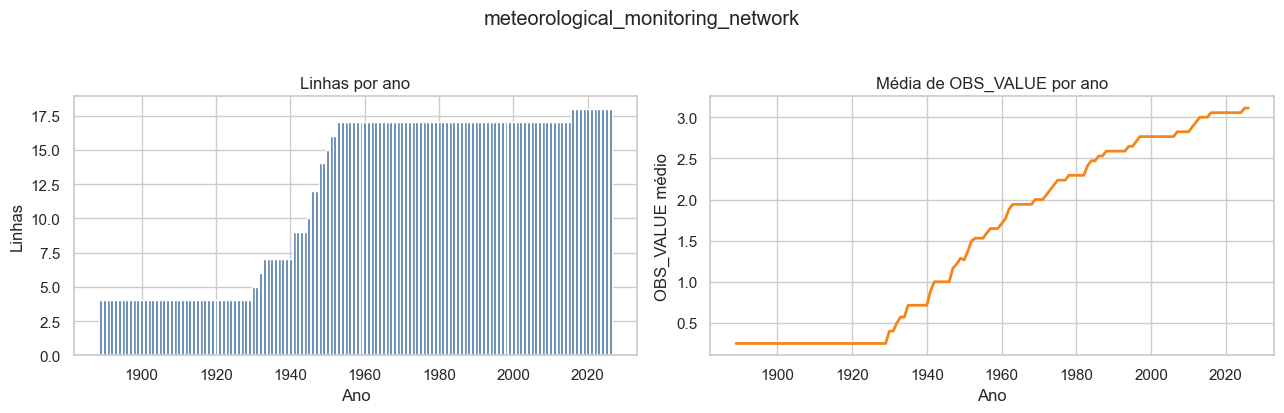

In [19]:
explore_folder('meteorological_monitoring_network')

## 3.16. `meteorological_monitoring_network_disaggregated`: Meteorological monitoring network - disaggregated

Tipo informado nos metadados: `dotstat_csv`.

Dataset: meteorological_monitoring_network_disaggregated
Metadados


,field,value
0,title,Meteorological monitoring network - disaggregated
1,type,dotstat_csv
2,dataflow,DF_METEO_MONITOR_NET
3,key,A..
4,downloaded_at_utc,2026-06-10T17:17:15+00:00
5,source_url,"https://stats.pacificdata.org/vis?lc=en&df[ds]=SPC2&df[id]=DF_METEO_MONITOR_NET&df[ag]=SPC&df[vs]=1.0&av=true&dq=A..&pd=,&to[TIME_PERIOD]=false"
6,api_url,"https://stats-nsi-stable.pacificdata.org/rest/data/SPC,DF_METEO_MONITOR_NET,1.0/A..?dimensionAtObservation=AllDimensions&format=csv"


Arquivos da pasta


,file,extension,size_mb,is_file
0,data.csv,.csv,0.09,True
1,metadata.json,.json,0.00,True


Estrutura


,dataset,rows,columns,memory_mb,duplicate_rows,duplicate_rows_pct,empty_columns,columns_list
0,meteorological_monitoring_network_disaggregated,1650,12,0.67,0,0.00,"OBS_STATUS, ERROR_TYPE, ERROR_VAL, OBS_COMMENT","DATAFLOW, FREQ, GEO_PICT, METEO_STATION_TYPE, TIME_PERIOD, OBS_VALUE, OBS_STATUS, UNIT_MEASURE, ERROR_TYPE, ERROR_VAL, REPORTING_TYPE, OBS_COMMENT"


... (6 outputs left out)

Resumo de OBS_VALUE


,valid_rows,missing_rows,missing_pct,min,p25,median,mean,p75,max,std,negative_values,zero_values
0,1650,0,0.00,0,0.00,2.00,2.05,3.00,8,1.86,0,414


Categorias mais frequentes


,column,value,rows,rows_pct
0,GEO_PICT,NR,138,8.36
1,GEO_PICT,WS,138,8.36
2,GEO_PICT,PN,138,8.36
3,GEO_PICT,NU,138,8.36
4,GEO_PICT,PF,97,5.88
5,GEO_PICT,TV,95,5.76
6,GEO_PICT,FJ,94,5.70
7,GEO_PICT,FM,86,5.21
8,GEO_PICT,NC,86,5.21
9,GEO_PICT,MH,82,4.97


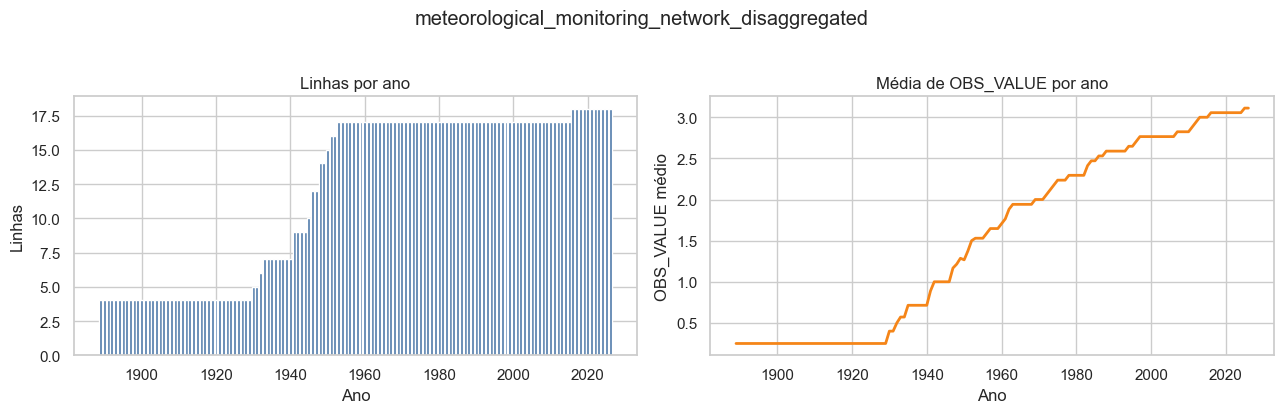

In [20]:
explore_folder('meteorological_monitoring_network_disaggregated')

## 3.17. `population_growth`: Population growth

Tipo informado nos metadados: `dotstat_csv`.

Dataset: population_growth
Metadados


,field,value
0,title,Population growth
1,type,dotstat_csv
2,dataflow,DF_NMDI_POP
3,key,A..NMDI0002._T._T._T..
4,downloaded_at_utc,2026-06-10T17:17:15+00:00
5,source_url,https://stats.pacificdata.org/vis?tm=population%20growth&pg=0&snb=11&df[ds]=ds%3ASPC2&df[id]=DF_NMDI_POP&df[ag]=SPC&df[vs]=1.0&dq=A..NMDI0002._T._T._T..&pd=...
6,api_url,"https://stats-nsi-stable.pacificdata.org/rest/data/SPC,DF_NMDI_POP,1.0/A..NMDI0002._T._T._T..?dimensionAtObservation=AllDimensions&format=csv"


Arquivos da pasta


,file,extension,size_mb,is_file
0,data.csv,.csv,0.08,True
1,metadata.json,.json,0.00,True


Estrutura


,dataset,rows,columns,memory_mb,duplicate_rows,duplicate_rows_pct,empty_columns,columns_list
0,population_growth,792,16,0.60,0,0.00,"UNIT_MULT, OBS_COMMENT","DATAFLOW, FREQ, GEO_PICT, INDICATOR, SEX, AGE, URBANIZATION, DISABILITY, COMPOSITE_BREAKDOWN, TIME_PERIOD, OBS_VALUE, UNIT_MEASURE, UNIT_MULT, OBS_STATUS (+2)"


... (6 outputs left out)

Resumo de OBS_VALUE


,valid_rows,missing_rows,missing_pct,min,p25,median,mean,p75,max,std,negative_values,zero_values
0,792,0,0.00,-30.30,-0.20,0.62,0.70,1.82,65.00,3.47,227,14


Categorias mais frequentes


,column,value,rows,rows_pct
0,GEO_PICT,PW,36,4.55
1,GEO_PICT,MP,36,4.55
2,GEO_PICT,NC,36,4.55
3,GEO_PICT,PG,36,4.55
4,GEO_PICT,KI,36,4.55
5,GEO_PICT,FJ,36,4.55
6,GEO_PICT,FM,36,4.55
7,GEO_PICT,GU,36,4.55
8,GEO_PICT,TO,36,4.55
9,GEO_PICT,PF,36,4.55


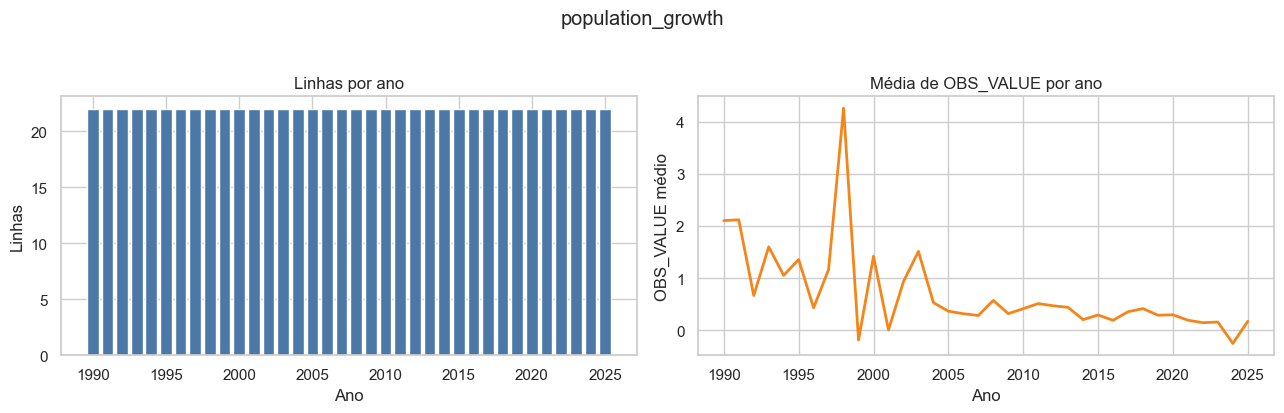

In [21]:
explore_folder('population_growth')

## 3.18. `power_generation`: Power generation

Tipo informado nos metadados: `dotstat_csv`.

Dataset: power_generation
Metadados


,field,value
0,title,Power generation
1,type,dotstat_csv
2,dataflow,DF_CLIMATE_CHANGE
3,key,A.POWER_GEN.
4,downloaded_at_utc,2026-06-10T17:17:15+00:00
5,source_url,"https://stats.pacificdata.org/vis?lc=en&df[ds]=SPC2&df[id]=DF_CLIMATE_CHANGE&df[ag]=SPC&df[vs]=1.0&av=true&dq=A.POWER_GEN.&pd=,&to[TIME_PERIOD]=false"
6,api_url,"https://stats-nsi-stable.pacificdata.org/rest/data/SPC,DF_CLIMATE_CHANGE,1.0/A.POWER_GEN.?dimensionAtObservation=AllDimensions&format=csv"


Arquivos da pasta


,file,extension,size_mb,is_file
0,data.csv,.csv,0.03,True
1,metadata.json,.json,0.00,True


Estrutura


,dataset,rows,columns,memory_mb,duplicate_rows,duplicate_rows_pct,empty_columns,columns_list
0,power_generation,432,12,0.18,0,0.00,"OBS_STATUS, ERROR_TYPE, ERROR_VAL, OBS_COMMENT","DATAFLOW, FREQ, CLIMATE_CHANGE_INDICATORS, GEO_PICT, TIME_PERIOD, OBS_VALUE, OBS_STATUS, UNIT_MEASURE, ERROR_TYPE, ERROR_VAL, REPORTING_TYPE, OBS_COMMENT"


... (6 outputs left out)

Resumo de OBS_VALUE


,valid_rows,missing_rows,missing_pct,min,p25,median,mean,p75,max,std,negative_values,zero_values
0,432,0,0.00,0.60,32.55,78.65,522.32,669.95,"3,508.30",896.56,0,0


Categorias mais frequentes


,column,value,rows,rows_pct
0,GEO_PICT,NR,24,5.56
1,GEO_PICT,NU,24,5.56
2,GEO_PICT,FM,24,5.56
3,GEO_PICT,VU,24,5.56
4,GEO_PICT,PW,24,5.56
5,GEO_PICT,GU,24,5.56
6,GEO_PICT,PF,24,5.56
7,GEO_PICT,MH,24,5.56
8,GEO_PICT,NC,24,5.56
9,GEO_PICT,FJ,24,5.56


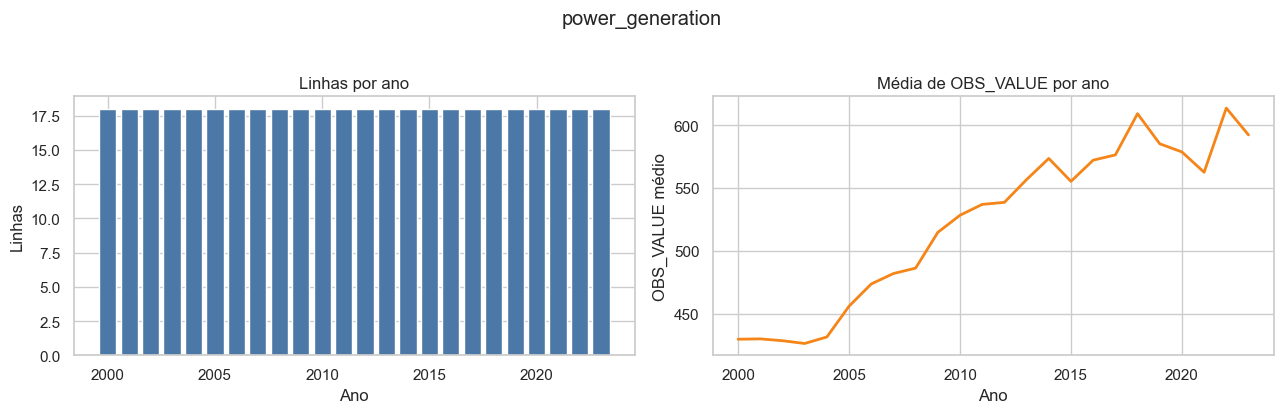

In [22]:
explore_folder('power_generation')

## 3.19. `power_generation_disaggregated`: Power generation - disaggregated

Tipo informado nos metadados: `dotstat_csv`.

Dataset: power_generation_disaggregated
Metadados


,field,value
0,title,Power generation - disaggregated
1,type,dotstat_csv
2,dataflow,DF_POWER_GEN
3,key,A...
4,downloaded_at_utc,2026-06-10T17:17:15+00:00
5,source_url,"https://stats.pacificdata.org/vis?lc=en&df[ds]=SPC2&df[id]=DF_POWER_GEN&df[ag]=SPC&df[vs]=1.0&av=true&dq=A...&pd=,&to[TIME_PERIOD]=false"
6,api_url,"https://stats-nsi-stable.pacificdata.org/rest/data/SPC,DF_POWER_GEN,1.0/A...?dimensionAtObservation=AllDimensions&format=csv"


Arquivos da pasta


,file,extension,size_mb,is_file
0,data.csv,.csv,0.29,True
1,metadata.json,.json,0.00,True


Estrutura


,dataset,rows,columns,memory_mb,duplicate_rows,duplicate_rows_pct,empty_columns,columns_list
0,power_generation_disaggregated,5300,13,2.44,0,0.00,"OBS_STATUS, ERROR_TYPE, ERROR_VAL, OBS_COMMENT","DATAFLOW, FREQ, GEO_PICT, ENERGY_SOURCE, GRID_CONN, TIME_PERIOD, OBS_VALUE, OBS_STATUS, UNIT_MEASURE, ERROR_TYPE, ERROR_VAL, REPORTING_TYPE, OBS_COMMENT"


... (6 outputs left out)

Resumo de OBS_VALUE


,valid_rows,missing_rows,missing_pct,min,p25,median,mean,p75,max,std,negative_values,zero_values
0,5300,0,0.00,0.00,0.60,8.25,170.30,85.90,"3,076.40",397.23,0,421


Categorias mais frequentes


,column,value,rows,rows_pct
0,GEO_PICT,PG,502,9.47
1,GEO_PICT,FJ,474,8.94
2,GEO_PICT,NC,397,7.49
3,GEO_PICT,PF,380,7.17
4,GEO_PICT,WS,368,6.94
5,GEO_PICT,SB,334,6.30
6,GEO_PICT,VU,333,6.28
7,GEO_PICT,CK,298,5.62
8,GEO_PICT,TV,272,5.13
9,GEO_PICT,FM,260,4.91


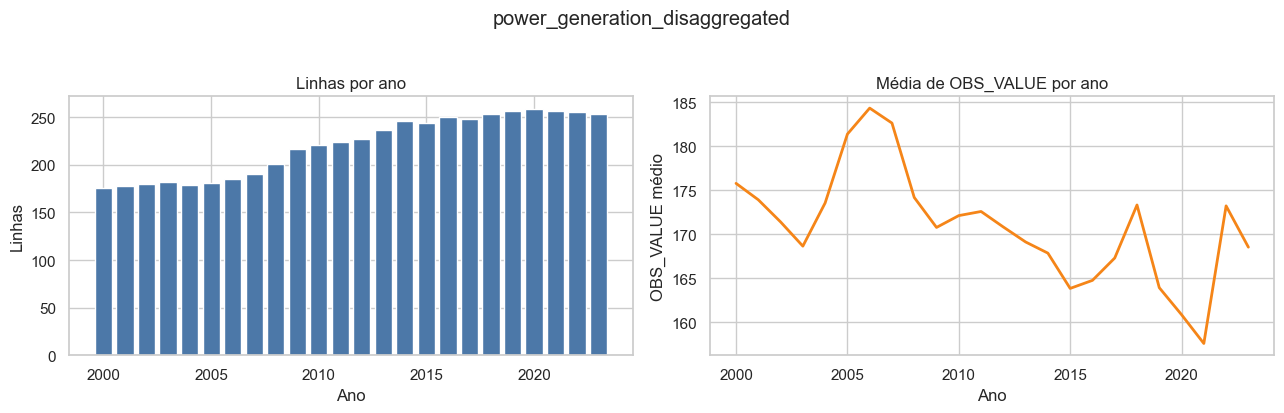

In [23]:
explore_folder('power_generation_disaggregated')

## 3.20. `rainfall_anomalies`: Rainfall anomalies

Tipo informado nos metadados: `dotstat_csv`.

Dataset: rainfall_anomalies
Metadados


,field,value
0,title,Rainfall anomalies
1,type,dotstat_csv
2,dataflow,DF_CLIMATE_CHANGE
3,key,A.RAIN_ANOM.
4,downloaded_at_utc,2026-06-10T17:17:15+00:00
5,source_url,"https://stats.pacificdata.org/vis?lc=en&df[ds]=SPC2&df[id]=DF_CLIMATE_CHANGE&df[ag]=SPC&df[vs]=1.0&av=true&dq=A.RAIN_ANOM.&pd=,&to[TIME_PERIOD]=false"
6,api_url,"https://stats-nsi-stable.pacificdata.org/rest/data/SPC,DF_CLIMATE_CHANGE,1.0/A.RAIN_ANOM.?dimensionAtObservation=AllDimensions&format=csv"


Arquivos da pasta


,file,extension,size_mb,is_file
0,data.csv,.csv,0.07,True
1,metadata.json,.json,0.00,True


Estrutura


,dataset,rows,columns,memory_mb,duplicate_rows,duplicate_rows_pct,empty_columns,columns_list
0,rainfall_anomalies,1034,12,0.48,0,0.00,"OBS_STATUS, OBS_COMMENT","DATAFLOW, FREQ, CLIMATE_CHANGE_INDICATORS, GEO_PICT, TIME_PERIOD, OBS_VALUE, OBS_STATUS, UNIT_MEASURE, ERROR_TYPE, ERROR_VAL, REPORTING_TYPE, OBS_COMMENT"


... (6 outputs left out)

Resumo de OBS_VALUE


,valid_rows,missing_rows,missing_pct,min,p25,median,mean,p75,max,std,negative_values,zero_values
0,1034,0,0.00,-54.40,-8.78,-0.75,-0.83,7.15,66.60,14.04,540,2


Categorias mais frequentes


,column,value,rows,rows_pct
0,GEO_PICT,TK,47,4.55
1,GEO_PICT,MH,47,4.55
2,GEO_PICT,NR,47,4.55
3,GEO_PICT,FJ,47,4.55
4,GEO_PICT,CK,47,4.55
5,GEO_PICT,TV,47,4.55
6,GEO_PICT,AS,47,4.55
7,GEO_PICT,WS,47,4.55
8,GEO_PICT,PW,47,4.55
9,GEO_PICT,PG,47,4.55


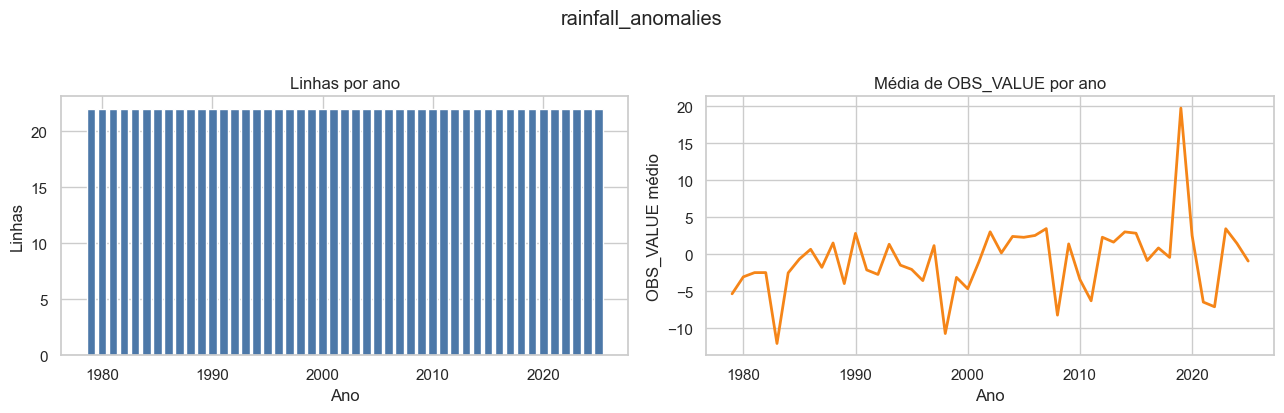

In [24]:
explore_folder('rainfall_anomalies')

## 3.21. `red_list_index`: Red List Index

Tipo informado nos metadados: `dotstat_csv`.

Dataset: red_list_index
Metadados


,field,value
0,title,Red List Index
1,type,dotstat_csv
2,dataflow,DF_SDG_15
3,key,A.ER_RSK_LST.........
4,downloaded_at_utc,2026-06-10T17:17:15+00:00
5,source_url,"https://stats.pacificdata.org/vis?lc=en&df[ds]=ds%3ASPC2&df[id]=DF_SDG_15&df[ag]=SPC&df[vs]=3.0&dq=A.ER_RSK_LST.........&pd=,&to[TIME_PERIOD]=false"
6,api_url,"https://stats-nsi-stable.pacificdata.org/rest/data/SPC,DF_SDG_15,3.0/A.ER_RSK_LST.........?dimensionAtObservation=AllDimensions&format=csv"


Arquivos da pasta


,file,extension,size_mb,is_file
0,data.csv,.csv,0.28,True
1,metadata.json,.json,0.00,True


Estrutura


,dataset,rows,columns,memory_mb,duplicate_rows,duplicate_rows_pct,empty_columns,columns_list
0,red_list_index,704,20,0.89,0,0.00,"OBS_STATUS, OBS_COMMENT","DATAFLOW, FREQ, INDICATOR, GEO_PICT, SEX, AGE, URBANIZATION, INCOME, EDUCATION, OCCUPATION, COMPOSITE_BREAKDOWN, DISABILITY, TIME_PERIOD, OBS_VALUE (+6)"


... (6 outputs left out)

Resumo de OBS_VALUE


,valid_rows,missing_rows,missing_pct,min,p25,median,mean,p75,max,std,negative_values,zero_values
0,704,0,0.00,0.36,0.72,0.79,0.78,0.85,0.95,0.10,0,0


Categorias mais frequentes


,column,value,rows,rows_pct
0,GEO_PICT,TO,32,4.55
1,GEO_PICT,TV,32,4.55
2,GEO_PICT,TK,32,4.55
3,GEO_PICT,VU,32,4.55
4,GEO_PICT,SB,32,4.55
5,GEO_PICT,WS,32,4.55
6,GEO_PICT,KI,32,4.55
7,GEO_PICT,NC,32,4.55
8,GEO_PICT,PW,32,4.55
9,GEO_PICT,PF,32,4.55


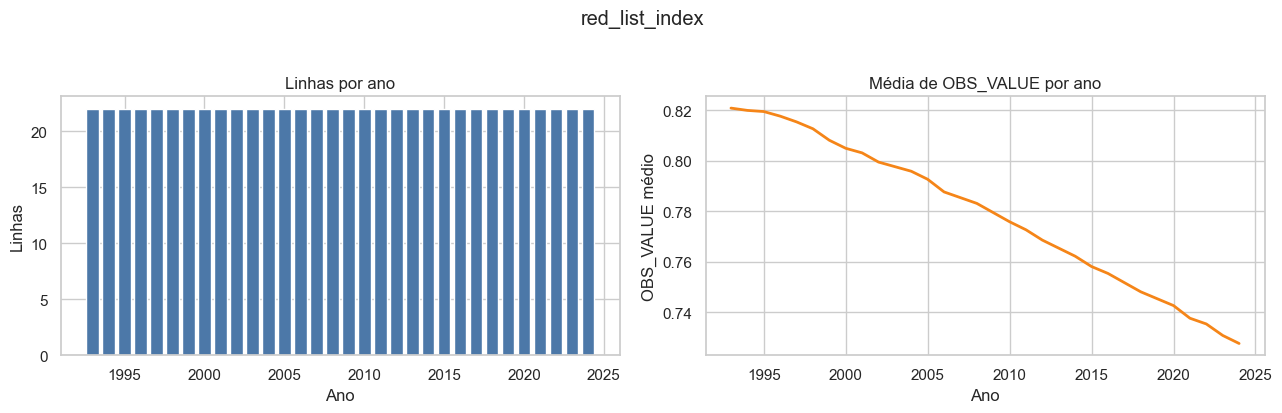

In [25]:
explore_folder('red_list_index')

## 3.22. `renewable_energy_share_total_final_energy_consumption`: Renewable energy share in the total final energy consumption

Tipo informado nos metadados: `dotstat_csv`.

Dataset: renewable_energy_share_total_final_energy_consumption
Metadados


,field,value
0,title,Renewable energy share in the total final energy consumption
1,type,dotstat_csv
2,dataflow,DF_SDG
3,key,A.EG_FEC_RNEW.._T._T._T._T._T._T._Z._T
4,downloaded_at_utc,2026-06-10T17:17:15+00:00
5,source_url,"https://stats.pacificdata.org/vis?fs[0]=Development%20indicators,0%7CSustainable%20Development%20Goals%23SDG%23&pg=0&fc=Development%20indicators&bp=true&snb..."
6,api_url,"https://stats-nsi-stable.pacificdata.org/rest/data/SPC,DF_SDG,3.0/A.EG_FEC_RNEW.._T._T._T._T._T._T._Z._T?dimensionAtObservation=AllDimensions&format=csv"


Arquivos da pasta


,file,extension,size_mb,is_file
0,data.csv,.csv,0.06,True
1,metadata.json,.json,0.00,True


Estrutura


,dataset,rows,columns,memory_mb,duplicate_rows,duplicate_rows_pct,empty_columns,columns_list
0,renewable_energy_share_total_final_energy_consumption,461,20,0.46,0,0.00,"OBS_STATUS, OBS_COMMENT","DATAFLOW, FREQ, INDICATOR, GEO_PICT, SEX, AGE, URBANIZATION, INCOME, EDUCATION, OCCUPATION, COMPOSITE_BREAKDOWN, DISABILITY, TIME_PERIOD, OBS_VALUE (+6)"


... (6 outputs left out)

Resumo de OBS_VALUE


,valid_rows,missing_rows,missing_pct,min,p25,median,mean,p75,max,std,negative_values,zero_values
0,461,0,0.00,0.00,0.60,5.10,15.97,33.75,66.38,19.99,0,52


Categorias mais frequentes


,column,value,rows,rows_pct
0,GEO_PICT,PF,24,5.21
1,GEO_PICT,AS,23,4.99
2,GEO_PICT,CK,23,4.99
3,GEO_PICT,WF,23,4.99
4,GEO_PICT,VU,23,4.99
5,GEO_PICT,TV,23,4.99
6,GEO_PICT,TO,23,4.99
7,GEO_PICT,SB,23,4.99
8,GEO_PICT,PW,23,4.99
9,GEO_PICT,PG,23,4.99


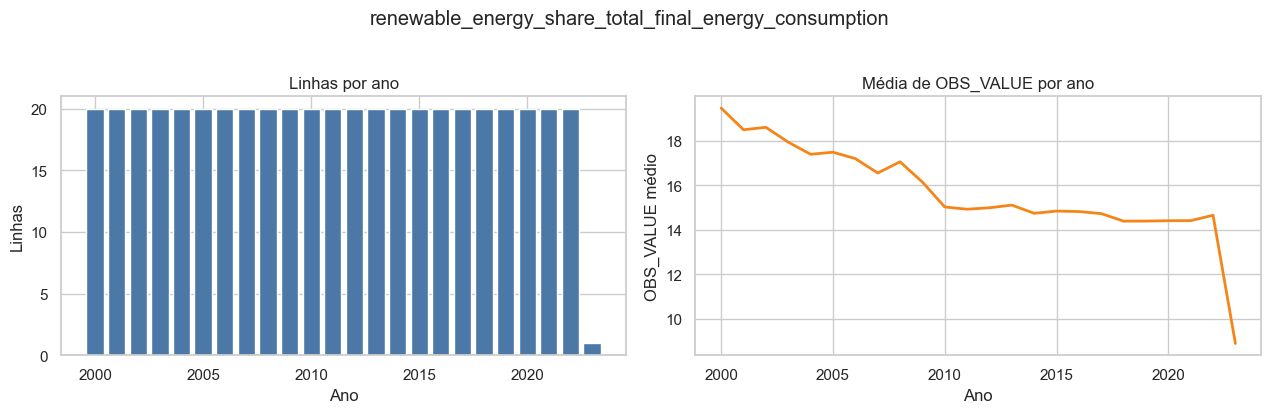

In [26]:
explore_folder('renewable_energy_share_total_final_energy_consumption')

## 3.23. `safely_managed_drinking_water_services`: Proportion of population using safely managed drinking water services

Tipo informado nos metadados: `dotstat_csv`.

Dataset: safely_managed_drinking_water_services
Metadados


,field,value
0,title,Proportion of population using safely managed drinking water services
1,type,dotstat_csv
2,dataflow,DF_SDG_06
3,key,A.SH_H2O_SAFE...._T.....
4,downloaded_at_utc,2026-06-10T17:17:15+00:00
5,source_url,"https://stats.pacificdata.org/vis?lc=en&df[ds]=ds%3ASPC2&df[id]=DF_SDG_06&df[ag]=SPC&df[vs]=3.0&dq=A.SH_H2O_SAFE...._T.....&pd=,&to[TIME_PERIOD]=false"
6,api_url,"https://stats-nsi-stable.pacificdata.org/rest/data/SPC,DF_SDG_06,3.0/A.SH_H2O_SAFE...._T.....?dimensionAtObservation=AllDimensions&format=csv"


Arquivos da pasta


,file,extension,size_mb,is_file
0,data.csv,.csv,0.05,True
1,metadata.json,.json,0.00,True


Estrutura


,dataset,rows,columns,memory_mb,duplicate_rows,duplicate_rows_pct,empty_columns,columns_list
0,safely_managed_drinking_water_services,430,20,0.41,0,0.00,"OBS_STATUS, OBS_COMMENT","DATAFLOW, FREQ, INDICATOR, GEO_PICT, SEX, AGE, URBANIZATION, INCOME, EDUCATION, OCCUPATION, COMPOSITE_BREAKDOWN, DISABILITY, TIME_PERIOD, OBS_VALUE (+6)"


... (6 outputs left out)

Resumo de OBS_VALUE


,valid_rows,missing_rows,missing_pct,min,p25,median,mean,p75,max,std,negative_values,zero_values
0,430,0,0.00,31.71,83.69,90.40,86.75,98.07,100.00,15.03,0,0


Categorias mais frequentes


,column,value,rows,rows_pct
0,GEO_PICT,FJ,23,5.35
1,GEO_PICT,NU,23,5.35
2,GEO_PICT,PF,23,5.35
3,GEO_PICT,WF,23,5.35
4,GEO_PICT,MP,23,5.35
5,GEO_PICT,TV,23,5.35
6,GEO_PICT,KI,23,5.35
7,GEO_PICT,CK,23,5.35
8,GEO_PICT,WS,23,5.35
9,GEO_PICT,VU,23,5.35


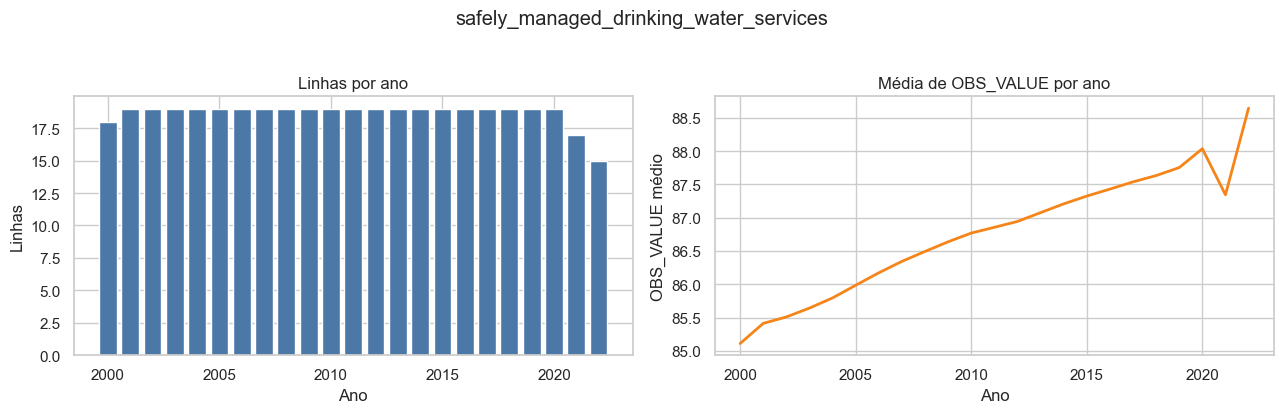

In [27]:
explore_folder('safely_managed_drinking_water_services')

## 3.24. `sea_level_anomalies`: Sea level anomalies

Tipo informado nos metadados: `dotstat_csv`.

Dataset: sea_level_anomalies
Metadados


,field,value
0,title,Sea level anomalies
1,type,dotstat_csv
2,dataflow,DF_CLIMATE_CHANGE
3,key,A.SEA_LVL.
4,downloaded_at_utc,2026-06-10T17:17:15+00:00
5,source_url,"https://stats.pacificdata.org/vis?lc=en&df[ds]=SPC2&df[id]=DF_CLIMATE_CHANGE&df[ag]=SPC&df[vs]=1.0&av=true&dq=A.SEA_LVL.&pd=,&to[TIME_PERIOD]=false"
6,api_url,"https://stats-nsi-stable.pacificdata.org/rest/data/SPC,DF_CLIMATE_CHANGE,1.0/A.SEA_LVL.?dimensionAtObservation=AllDimensions&format=csv"


Arquivos da pasta


,file,extension,size_mb,is_file
0,data.csv,.csv,0.04,True
1,metadata.json,.json,0.00,True


Estrutura


,dataset,rows,columns,memory_mb,duplicate_rows,duplicate_rows_pct,empty_columns,columns_list
0,sea_level_anomalies,651,12,0.27,0,0.00,"OBS_STATUS, ERROR_TYPE, ERROR_VAL, OBS_COMMENT","DATAFLOW, FREQ, CLIMATE_CHANGE_INDICATORS, GEO_PICT, TIME_PERIOD, OBS_VALUE, OBS_STATUS, UNIT_MEASURE, ERROR_TYPE, ERROR_VAL, REPORTING_TYPE, OBS_COMMENT"


... (6 outputs left out)

Resumo de OBS_VALUE


,valid_rows,missing_rows,missing_pct,min,p25,median,mean,p75,max,std,negative_values,zero_values
0,651,0,0.00,-0.20,0.00,0.00,0.05,0.10,0.20,0.06,24,321


Categorias mais frequentes


,column,value,rows,rows_pct
0,GEO_PICT,KI,31,4.76
1,GEO_PICT,MP,31,4.76
2,GEO_PICT,GU,31,4.76
3,GEO_PICT,NC,31,4.76
4,GEO_PICT,TO,31,4.76
5,GEO_PICT,FM,31,4.76
6,GEO_PICT,VU,31,4.76
7,GEO_PICT,MH,31,4.76
8,GEO_PICT,WF,31,4.76
9,GEO_PICT,PF,31,4.76


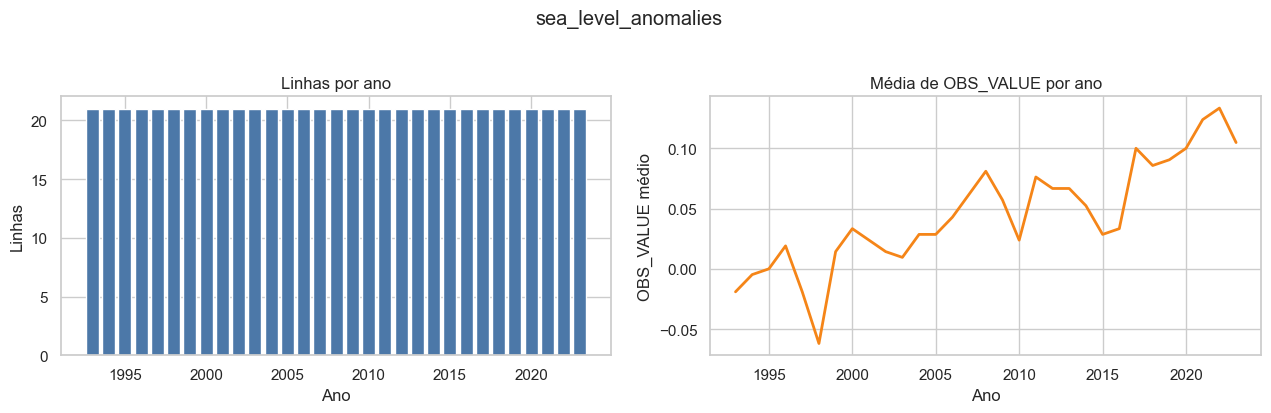

In [28]:
explore_folder('sea_level_anomalies')

## 3.25. `tourist_arrivals`: Tourist arrivals

Tipo informado nos metadados: `dotstat_csv`.

Dataset: tourist_arrivals
Metadados


,field,value
0,title,Tourist arrivals
1,type,dotstat_csv
2,dataflow,DF_CLIMATE_CHANGE
3,key,A.TRSM_ARR.
4,downloaded_at_utc,2026-06-10T17:17:15+00:00
5,source_url,"https://stats.pacificdata.org/vis?lc=en&df[ds]=SPC2&df[id]=DF_CLIMATE_CHANGE&df[ag]=SPC&df[vs]=1.0&av=true&dq=A.TRSM_ARR.&pd=,&to[TIME_PERIOD]=false"
6,api_url,"https://stats-nsi-stable.pacificdata.org/rest/data/SPC,DF_CLIMATE_CHANGE,1.0/A.TRSM_ARR.?dimensionAtObservation=AllDimensions&format=csv"


Arquivos da pasta


,file,extension,size_mb,is_file
0,data.csv,.csv,0.01,True
1,metadata.json,.json,0.00,True


Estrutura


,dataset,rows,columns,memory_mb,duplicate_rows,duplicate_rows_pct,empty_columns,columns_list
0,tourist_arrivals,229,12,0.08,0,0.00,"OBS_STATUS, ERROR_TYPE, ERROR_VAL, REPORTING_TYPE, OBS_COMMENT","DATAFLOW, FREQ, CLIMATE_CHANGE_INDICATORS, GEO_PICT, TIME_PERIOD, OBS_VALUE, OBS_STATUS, UNIT_MEASURE, ERROR_TYPE, ERROR_VAL, REPORTING_TYPE, OBS_COMMENT"


... (6 outputs left out)

Resumo de OBS_VALUE


,valid_rows,missing_rows,missing_pct,min,p25,median,mean,p75,max,std,negative_values,zero_values
0,229,0,0.00,200,"65,800.00","167,000.00","250,216.54","390,000.00",1058000,"236,885.35",0,0


Categorias mais frequentes


,column,value,rows,rows_pct
0,GEO_PICT,NC,30,13.10
1,GEO_PICT,FJ,29,12.66
2,GEO_PICT,TO,28,12.23
3,GEO_PICT,MP,28,12.23
4,GEO_PICT,VU,27,11.79
5,GEO_PICT,PF,21,9.17
6,GEO_PICT,WS,17,7.42
7,GEO_PICT,KI,15,6.55
8,GEO_PICT,PG,15,6.55
9,GEO_PICT,AS,10,4.37


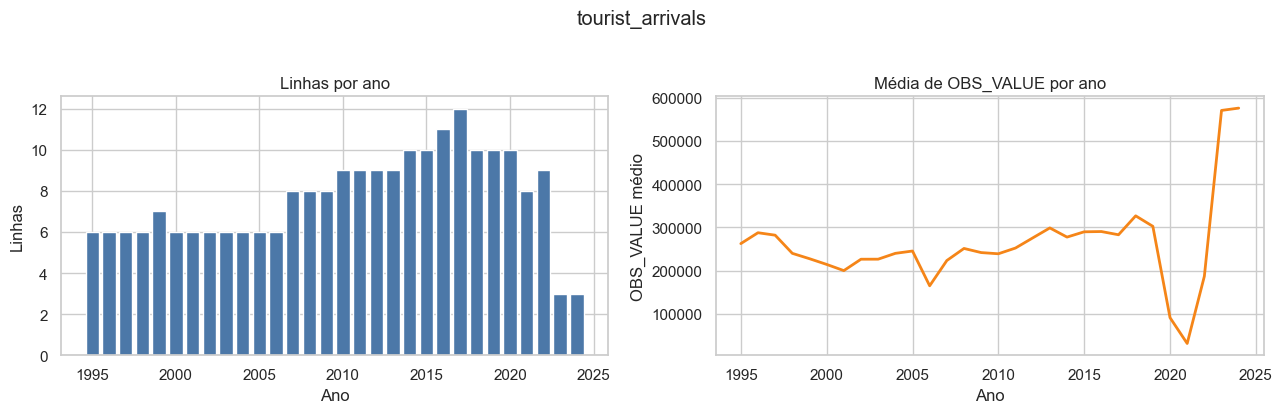

In [29]:
explore_folder('tourist_arrivals')

## 3.26. `tourist_arrivals_disaggregated`: Tourist arrivals - disaggregated

Tipo informado nos metadados: `dotstat_csv`.

Dataset: tourist_arrivals_disaggregated
Metadados


,field,value
0,title,Tourist arrivals - disaggregated
1,type,dotstat_csv
2,dataflow,DF_TOURISM_ARRIVALS
3,key,A..
4,downloaded_at_utc,2026-06-10T17:17:15+00:00
5,source_url,"https://stats.pacificdata.org/vis?lc=en&df[ds]=SPC2&df[id]=DF_TOURISM_ARRIVALS&df[ag]=SPC&df[vs]=1.0&av=true&dq=A..&pd=,&to[TIME_PERIOD]=false"
6,api_url,"https://stats-nsi-stable.pacificdata.org/rest/data/SPC,DF_TOURISM_ARRIVALS,1.0/A..?dimensionAtObservation=AllDimensions&format=csv"


Arquivos da pasta


,file,extension,size_mb,is_file
0,data.csv,.csv,0.04,True
1,metadata.json,.json,0.00,True


Estrutura


,dataset,rows,columns,memory_mb,duplicate_rows,duplicate_rows_pct,empty_columns,columns_list
0,tourist_arrivals_disaggregated,707,12,0.25,0,0.00,"OBS_STATUS, ERROR_TYPE, ERROR_VAL, REPORTING_TYPE, OBS_COMMENT","DATAFLOW, FREQ, GEO_PICT, VISITOR_DURATION_CAT, TIME_PERIOD, OBS_VALUE, OBS_STATUS, UNIT_MEASURE, ERROR_TYPE, ERROR_VAL, REPORTING_TYPE, OBS_COMMENT"


... (6 outputs left out)

Resumo de OBS_VALUE


,valid_rows,missing_rows,missing_pct,min,p25,median,mean,p75,max,std,negative_values,zero_values
0,707,0,0.00,35,"9,000.00","46,000.00","140,853.40","121,000.00",1667000,"268,690.93",0,0


Categorias mais frequentes


,column,value,rows,rows_pct
0,GEO_PICT,NC,57,8.06
1,GEO_PICT,FJ,56,7.92
2,GEO_PICT,MP,56,7.92
3,GEO_PICT,TO,55,7.78
4,GEO_PICT,VU,54,7.64
5,GEO_PICT,PF,49,6.93
6,GEO_PICT,WS,44,6.22
7,GEO_PICT,KI,43,6.08
8,GEO_PICT,PG,41,5.80
9,GEO_PICT,AS,33,4.67


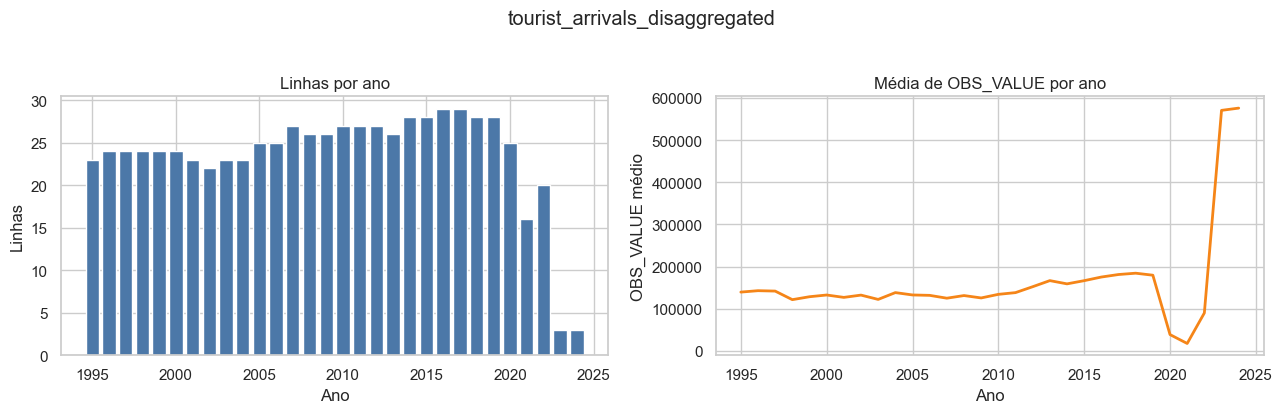

In [30]:
explore_folder('tourist_arrivals_disaggregated')

## 3.27. `tuberculosis_incidence_per_100000_population`: Tuberculosis incidence per 100,000 population

Tipo informado nos metadados: `dotstat_csv`.

Dataset: tuberculosis_incidence_per_100000_population
Metadados


,field,value
0,title,"Tuberculosis incidence per 100,000 population"
1,type,dotstat_csv
2,dataflow,DF_SDG_03
3,key,A.SH_TBS_INCD.........
4,downloaded_at_utc,2026-06-10T17:17:15+00:00
5,source_url,"https://stats.pacificdata.org/vis?lc=en&df[ds]=ds%3ASPC2&df[id]=DF_SDG_03&df[ag]=SPC&df[vs]=3.0&dq=A.SH_TBS_INCD.........&pd=,&to[TIME_PERIOD]=false"
6,api_url,"https://stats-nsi-stable.pacificdata.org/rest/data/SPC,DF_SDG_03,3.0/A.SH_TBS_INCD.........?dimensionAtObservation=AllDimensions&format=csv"


Arquivos da pasta


,file,extension,size_mb,is_file
0,data.csv,.csv,0.14,True
1,metadata.json,.json,0.00,True


Estrutura


,dataset,rows,columns,memory_mb,duplicate_rows,duplicate_rows_pct,empty_columns,columns_list
0,tuberculosis_incidence_per_100000_population,504,20,0.60,0,0.00,OBS_STATUS,"DATAFLOW, FREQ, INDICATOR, GEO_PICT, SEX, AGE, URBANIZATION, INCOME, EDUCATION, OCCUPATION, COMPOSITE_BREAKDOWN, DISABILITY, TIME_PERIOD, OBS_VALUE (+6)"


... (6 outputs left out)

Resumo de OBS_VALUE


,valid_rows,missing_rows,missing_pct,min,p25,median,mean,p75,max,std,negative_values,zero_values
0,504,0,0.00,0.00,14.00,48.00,105.05,118.25,"1,180.00",144.35,0,44


Categorias mais frequentes


,column,value,rows,rows_pct
0,GEO_PICT,AS,24,4.76
1,GEO_PICT,PF,24,4.76
2,GEO_PICT,WF,24,4.76
3,GEO_PICT,VU,24,4.76
4,GEO_PICT,TV,24,4.76
5,GEO_PICT,TO,24,4.76
6,GEO_PICT,TK,24,4.76
7,GEO_PICT,SB,24,4.76
8,GEO_PICT,PW,24,4.76
9,GEO_PICT,PG,24,4.76


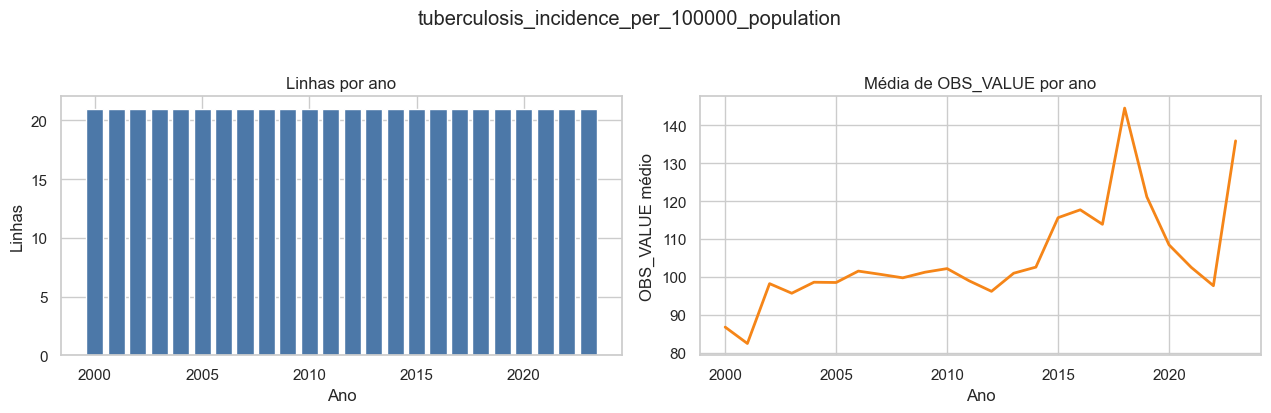

In [31]:
explore_folder('tuberculosis_incidence_per_100000_population')

## Próximos Passos Analíticos

Depois desta exploração inicial por pasta, os próximos passos naturais são: harmonizar os códigos `GEO_PICT`, decidir quais datasets agregados e desagregados serão usados na narrativa, padronizar unidades antes de comparar indicadores e escolher séries com boa cobertura temporal/geográfica para visualização final.